# From Raw Taxi Trips to Route Intelligence: A Predictive Pipeline Using NYC TLC Yellow Taxi Data

**Name:** Sunain Mushtaq  
**Student Number:** S224089221  
**Email:** s224089221@deakin.edu.au  
**Unit:** SIT220 Data Wrangling  
**Report version:** sklearn-based pandas workflow

<div style="
    border-left: 6px solid #2f6f73;
    padding: 14px 18px;
    background: transparent;
    border-radius: 6px;
    margin-top: 12px;
    border-top: 1px solid rgba(127,127,127,0.25);
    border-right: 1px solid rgba(127,127,127,0.25);
    border-bottom: 1px solid rgba(127,127,127,0.25);
">
<strong>Report focus.</strong> This notebook builds a reproducible route-intelligence pipeline from NYC TLC Yellow Taxi data. It validates and cleans raw Parquet files, engineers route-hour features, assigns continuous route relevance scores, and compares sklearn regression models for trip duration and fare-related outcomes.
</div>


# From Raw Taxi Trips to Route Intelligence: A Predictive Pipeline Using NYC TLC Yellow Taxi Data

**Name:** Sunain Mushtaq  
**Student Number:** S224089221  
**Email:** s224089221@deakin.edu.au  
**Unit:** SIT220 Data Wrangling  
**Report version:** sklearn-based pandas workflow  

<div style="
    border-left: 6px solid #2f6f73;
    padding: 14px 18px;
    background: transparent;
    border-radius: 6px;
    margin-top: 12px;
    border-top: 1px solid rgba(127,127,127,0.25);
    border-right: 1px solid rgba(127,127,127,0.25);
    border-bottom: 1px solid rgba(127,127,127,0.25);
">
<strong>Report focus.</strong> This report presents a complete data wrangling and predictive modelling pipeline using NYC TLC Yellow Taxi data. The workflow begins with raw monthly Parquet files and progresses through validation, cleaning, metadata integration, feature engineering, route-hour aggregation, route relevance scoring, sklearn modelling, evaluation, and business-oriented proxy interpretation.
</div>

# 1. Introduction and Problem Definition

NYC Yellow Taxi trip records provide a large-scale operational record of completed taxi movements across New York City. Each trip captures pickup and drop-off timestamps, taxi-zone identifiers, trip distance, passenger count, fare components, payment information, and other operational fields. This makes the dataset suitable for studying how urban taxi demand behaves across time, space, route corridors, and fare structures.

This report is designed as a continuous pipeline rather than a standalone modelling exercise. The analysis begins with raw TLC Parquet files and gradually transforms them into an analysis-ready route-intelligence layer. Each stage of the notebook supports the next: validation identifies data quality issues, cleaning removes invalid records, metadata joins make routes interpretable, feature engineering prepares trip-level predictors, route-hour aggregation reveals recurring travel corridors, and predictive modelling evaluates whether engineered features can estimate trip duration and fare-related outcomes.

The central idea of the project is to treat each pickup-to-drop-off taxi-zone pair as a recurring taxi corridor. These corridors are not fixed public transport routes. Instead, they are repeated historical movement patterns identified from completed taxi trips. By combining origin-destination pairs with pickup hour and day-of-week information, the notebook moves from individual trip records into a route-hour view of taxi behaviour. This allows the analysis to ask not only where taxis travel, but which routes recur, when they are most active, how reliable they are, and whether they carry commercial value.

The modelling task is positioned after the wrangling and feature-engineering stages. A simple sklearn Ridge regression model is used as a baseline for duration prediction, while a stronger HistGradientBoosting model is used to capture non-linear relationships between route, time, distance, and trip behaviour. A secondary fare model is included to support later business interpretation, but the main contribution remains the data pipeline and route-intelligence framework.

The business component is treated as an analytical extension rather than a direct claim about platform profitability or satisfaction. The TLC dataset does not directly contain customer satisfaction, driver satisfaction, driver payout, live driver availability, rejected requests, or platform costs. Therefore, the notebook uses route reliability, fare potential, demand recurrence, and scenario-based profit calculations as proxy indicators. This keeps the interpretation grounded in what the dataset can actually support.

<div style="border-left: 5px solid #70ad47; padding: 12px 16px; background-color: transparent; margin: 16px 0;">
<strong>Research question.</strong> How can NYC Yellow Taxi trip records be transformed into a route-level predictive pipeline that estimates trip duration, fare behaviour, and route relevance while providing a transparent foundation for future customer-driver optimisation and business feasibility analysis?
</div>

## 1.1 Research Problem

The research problem is to convert raw taxi trip data into a structured route-intelligence pipeline that can identify operationally meaningful route-hour combinations and use them to support prediction and interpretation. In raw form, the TLC data consists of millions of completed trip records. These records are useful, but they do not directly explain which routes are consistently important, which route patterns are reliable, or which trip-level features help predict travel time and fare behaviour.

To address this, the notebook restructures the data around recurring route-hour combinations. A route-hour combination is defined by pickup zone, drop-off zone, pickup day, and pickup hour. This framing is important because taxi demand is not only spatial; it is also temporal. A route that is highly active during weekday evening periods may not have the same operational relevance at other times. The route-hour structure therefore provides a more precise unit of analysis than simply counting trips between two zones.

The project frames route intelligence as a combination of four connected dimensions:

1. **Recurrence** — whether a route appears repeatedly across the selected period.  
2. **Reliability** — whether travel duration is relatively stable for that route-hour pattern.  
3. **Commercial value** — whether the route tends to produce meaningful fare outcomes.  
4. **Predictive usefulness** — whether engineered route and trip features help estimate duration and fare behaviour.  

These dimensions are then connected through the route relevance score and the predictive modelling stage.

### Research Questions

1. **Which pickup-to-drop-off zone pairs recur reliably across specific hours and days?**  
   This question investigates whether repeated taxi corridors can be identified when trips are grouped by both spatial and temporal structure. The goal is to detect recurring movement patterns rather than treat all trips as independent observations.

2. **Which engineered features most strongly explain trip duration and fare behaviour?**  
   This question examines whether temporal features, trip distance, borough movement, route frequency, route consistency, speed-related features, and route-level statistics provide useful predictive signal. It links the feature-engineering stage directly to model performance and interpretation.

3. **How can route relevance, predicted duration, and predicted fare support passenger-facing reliability and driver-facing value proxies?**  
   This question connects the technical pipeline to a business-oriented interpretation. More predictable routes may support passenger reliability, while routes with recurring demand and stronger fare potential may represent better driver-facing value. These are treated as proxy indicators rather than directly observed satisfaction or profit measures.

The TLC data contains completed trips only. It does not include live dispatch decisions, rejected trip requests, driver supply, customer ratings, driver ratings, waiting times, or platform-level costs. Because of this, the notebook avoids claiming that it directly measures customer satisfaction, driver satisfaction, or real platform profitability.

Instead, the project uses proxy-based interpretation. Lower duration variability is interpreted as a possible indicator of passenger-facing reliability. Repeated demand and fare potential are interpreted as possible indicators of driver-facing route value. Scenario-based PnL calculations are used only as a research extension to explore how passenger payment, assumed driver share, and operating cost could influence estimated margin.



## 1.2 End-to-End Pipeline Overview

The report follows the actual analytical flow of the notebook. Each stage produces an output that becomes the input for the next stage. This structure is important because the final models and business discussion are only meaningful after the data has been validated, cleaned, joined, engineered, and aggregated.

<table style="width:100%; border-collapse:collapse; margin:16px 0; font-size:14px;">
  <tr>
    <th style="border:1px solid #d9d9d9; padding:10px; text-align:left; width:8%;">Step</th>
    <th style="border:1px solid #d9d9d9; padding:10px; text-align:left; width:30%;">Pipeline Stage</th>
    <th style="border:1px solid #d9d9d9; padding:10px; text-align:left;">Role in the Research Pipeline</th>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">1</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Raw TLC data acquisition</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Loads January to March 2026 Yellow Taxi Parquet files and defines the study scope.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">2</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Schema inspection</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Checks available fields, data types, missing values, and key variables needed for route, fare, and duration analysis.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">3</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Validation and cleaning</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Identifies invalid durations, impossible distances, negative payments, out-of-scope timestamps, and extreme speeds before producing a clean analysis base.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">4</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Taxi-zone metadata integration</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Joins pickup and drop-off zone names and boroughs so route outputs become interpretable rather than only numeric IDs.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">5</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Trip-level feature engineering</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Creates temporal, distance, speed, fare, borough, and route features used for exploration, scoring, and model preparation.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">6</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Exploratory route analysis</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Examines hourly demand, route concentration, top recurring corridors, duration patterns, and distance relationships.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">7</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Route-hour aggregation</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Aggregates trips by pickup day, pickup hour, pickup zone, and drop-off zone to create the main route-intelligence table.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">8</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Route relevance scoring</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Builds a continuous score using demand frequency, fare potential, duration reliability, and recurrence to rank operationally useful route-hour combinations.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">9</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Prediction dataset preparation</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Creates sklearn-ready train/test datasets for duration and fare modelling using cleaned engineered features.</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">10</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Model training and evaluation</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Compares Ridge regression and HistGradientBoosting for duration prediction, then evaluates secondary fare prediction using MAE, RMSE, and R².</td>
  </tr>

  <tr>
    <td style="border:1px solid #d9d9d9; padding:10px;">11</td>
    <td style="border:1px solid #d9d9d9; padding:10px;"><strong>Business proxy interpretation</strong></td>
    <td style="border:1px solid #d9d9d9; padding:10px;">Uses route relevance, predicted duration, fare behaviour, and scenario assumptions to discuss passenger reliability, driver value, and platform-style margin trade-offs.</td>
  </tr>
</table>

The key design choice is to separate **route relevance scoring** from **predictive modelling**. Route relevance is calculated from interpretable aggregated behaviour, including demand frequency, fare potential, duration reliability, and recurrence. In contrast, sklearn regressors are trained to predict continuous trip-level outcomes such as trip duration and fare amount.

This separation makes the pipeline more analytically useful. The scoring stage explains which route-hour combinations appear operationally important, while the modelling stage tests whether engineered trip and route features can estimate uncertain outcomes. The later business section then uses these outputs as proxy evidence for customer reliability, driver value, and possible platform margin scenarios.

As a result, the notebook is structured as a research pipeline with three linked layers:

1. **Data engineering layer:** raw data loading, validation, cleaning, and feature construction.  
2. **Route intelligence layer:** route-hour aggregation, relevance scoring, spatial interpretation, and route ranking.  
3. **Predictive and business interpretation layer:** duration modelling, fare modelling, evaluation, satisfaction proxies, and PnL scenarios.  

Together, these layers show how raw taxi records can be transformed into a practical analytical framework for route-level decision support.

# 2. Data Acquisition and Scope Definition

The project uses official NYC Taxi and Limousine Commission (TLC) Yellow Taxi trip record data for January, February, and March 2026, together with the official TLC taxi-zone lookup table used to map numeric pickup and drop-off location identifiers into readable zone and borough metadata.

The selected three-month scope provides a balance between analytical depth, temporal coverage, and computational practicality. Using multiple consecutive months allows the notebook to capture recurring weekday/weekend behaviour, hourly congestion patterns, route repetition, and seasonal consistency across a sufficiently large operational dataset. This is particularly important for route-level aggregation and relevance scoring, where recurring corridor behaviour becomes more reliable when observed repeatedly over time rather than within a single isolated month.

The combined dataset contains more than 11 million raw Yellow Taxi trip records before cleaning. This scale is large enough to demonstrate realistic large-volume data wrangling challenges, including schema inspection, validation, missing-value handling, temporal filtering, metadata joins, and route-level aggregation. At the same time, the selected scope remains manageable within a notebook-oriented workflow using pandas-based preprocessing and sklearn modelling on a single-machine environment.

Yellow Taxi data was selected over other TLC collections because it contains detailed trip-level operational variables that directly support the project objectives. These include:
- pickup and drop-off timestamps,
- pickup and drop-off taxi-zone identifiers,
- trip distance,
- passenger counts,
- fare components,
- tip information,
- payment types,
- and total trip amounts.

These variables allow the notebook to support multiple analytical stages, including trip-duration modelling, fare prediction, temporal route analysis, route relevance scoring, and proxy-based operational interpretation.

The project intentionally focuses on completed trips rather than live dispatch behaviour. As a result, the scope is appropriate for studying historical route patterns, travel reliability, and recurring taxi-corridor behaviour, while acknowledging that real-time demand balancing, live driver allocation, and customer request rejection behaviour are outside the limits of the available TLC dataset.

## 2.1 Data Scope

Yellow Taxi records were selected because they contain detailed operational fields for completed trips: timestamps, trip distance, pickup and drop-off location IDs, passenger count, fare amount, total amount, surcharges, tolls, and tip amount. The dataset scope found in the local workspace contains three Parquet files:

- `yellow_tripdata_2026-01.parquet`: 3,724,889 rows
- `yellow_tripdata_2026-02.parquet`: 3,399,866 rows
- `yellow_tripdata_2026-03.parquet`: 3,952,451 rows

Together these files provide 11,077,206 raw records before cleaning.


In [85]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV

import geopandas as gpd
import folium
from folium.plugins import HeatMap

import joblib

In [19]:
# 2.2 Import libraries and configure report style

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid", context="notebook")
REPORT_PALETTE = sns.color_palette("crest", 8)
ACCENT_PALETTE = sns.color_palette("flare", 8)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#b8c2c2",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "grid.color": "#d9e2e1",
    "grid.linewidth": 0.7,
})

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)
RUN_TRAINING = True
SCOPE_START = pd.Timestamp("2026-01-01")
SCOPE_END = pd.Timestamp("2026-04-01")


def rmse_score(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)


def report_card(title, body, accent="#2f6f73"):
    display(HTML(f'''
    <div style="border-left:6px solid {accent}; padding:14px 18px; margin:12px 0; background:#f7fbfb; border-radius:6px; box-shadow:0 1px 4px rgba(0,0,0,0.06);">
        <div style="font-size:16px; font-weight:700; color:#1d3f42; margin-bottom:6px;">{title}</div>
        <div style="font-size:14px; line-height:1.55; color:#263636;">{body}</div>
    </div>
    '''))


report_card(
    "Environment status",
    f"Workflow: <strong>pandas + sklearn</strong>. Training flag: <strong>{RUN_TRAINING}</strong>. Date scope: <strong>{SCOPE_START.date()} to {(SCOPE_END - pd.Timedelta(days=1)).date()}</strong>. Model folder: <strong>{MODELS_DIR}</strong>.",
    accent="#33658a",
)

In [20]:
# 2.3 Define Data Paths

DATA_DIR = Path("data/raw")
ZONE_LOOKUP_PATH = Path("data/taxi_zone_lookup.csv")
PROCESSED_DIR = Path("data_processed")
FIGURES_DIR = Path("figures")
MODELS_DIR = Path("models")

PROCESSED_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

yellow_files = sorted(DATA_DIR.glob("yellow_tripdata_*.parquet"))

print(f"Number of Yellow Taxi files found: {len(yellow_files)}")
for file in yellow_files:
    print(file)

Number of Yellow Taxi files found: 3
data\raw\yellow_tripdata_2026-01.parquet
data\raw\yellow_tripdata_2026-02.parquet
data\raw\yellow_tripdata_2026-03.parquet


### File Scope Interpretation

The workspace contains three monthly Yellow Taxi Parquet files for January to March 2026. The row counts are substantial and reasonably balanced by month, ranging from about 3.40 million trips in February to about 3.95 million trips in March. This confirms that the analysis is not based on a small sample; it uses a multi-million-record operational dataset that can support route-hour aggregation and route relevance scoring.

The file-level date check shows a small amount of timestamp spillover around monthly boundaries, plus a historical outlier timestamp in the March file. The cleaning pipeline therefore enforces the selected pickup-date scope explicitly: trips must have pickup timestamps from 2026-01-01 up to but not including 2026-04-01. This keeps the report aligned with the stated Jan-Mar 2026 scope.


In [21]:
# 2.4 File Scope, Row Counts, and Date Range Before Full Loading
# This checks that the selected files match the Jan-Mar 2026 scope.

file_summaries = []

for file in yellow_files:
    try:
        temp_dates = pd.read_parquet(file, columns=["tpep_pickup_datetime"])
        file_summaries.append({
            "file": file.name,
            "rows": len(temp_dates),
            "min_pickup": temp_dates["tpep_pickup_datetime"].min(),
            "max_pickup": temp_dates["tpep_pickup_datetime"].max(),
        })
    except Exception as e:
        file_summaries.append(
            {"file": file.name, "rows": None, "min_pickup": None,
                "max_pickup": None, "error": str(e)}
        )

file_summary_df = pd.DataFrame(file_summaries)
file_summary_df

,file,rows,min_pickup,max_pickup
0,yellow_tripdata_2026-01.parquet,3724889,2025-12-31 23:57:29,2026-02-01 00:45:01
1,yellow_tripdata_2026-02.parquet,3399866,2026-01-31 23:31:23,2026-03-01 00:51:48
2,yellow_tripdata_2026-03.parquet,3952451,2008-12-31 23:03:20,2026-04-01 00:06:25


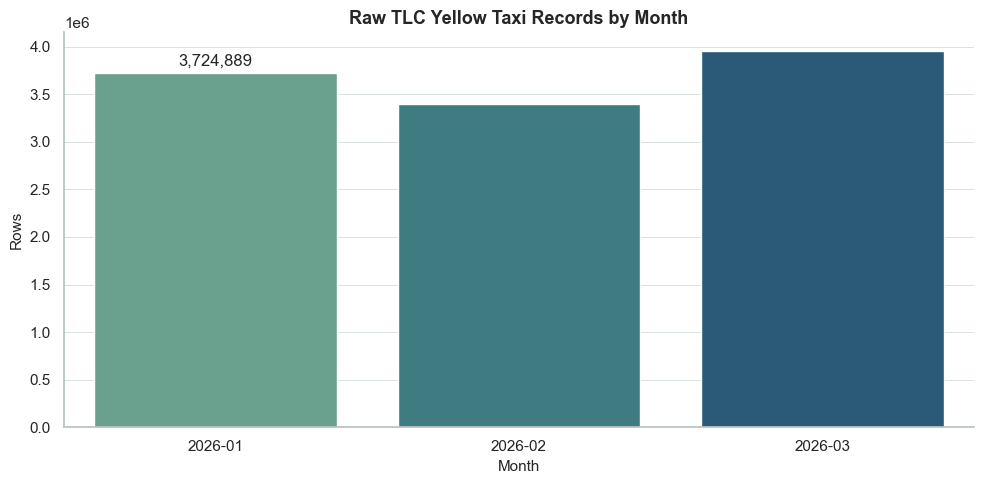

In [22]:
# 2.5 Visualise Row Counts by File
if not file_summary_df.empty and "rows" in file_summary_df.columns:
    plot_df = file_summary_df.dropna(subset=["rows"]).copy()
    plot_df["month"] = plot_df["file"].str.extract(r"(2026-\d{2})")
    if not plot_df.empty:
        plt.figure(figsize=(10, 5))
        ax = sns.barplot(data=plot_df, x="month", y="rows", palette="crest")
        ax.set_title("Raw TLC Yellow Taxi Records by Month")
        ax.set_xlabel("Month")
        ax.set_ylabel("Rows")
        # type: ignore
        # type: ignore
        ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
        sns.despine()
        plt.tight_layout()
        plt.show()

# 3. Raw Schema Inspection

Before cleaning, the raw files are inspected for field availability, data types, missing values, and obvious schema risks. This step checks whether the dataset contains the variables needed for time, location, distance, fare, and passenger-based modelling.


In [23]:
# 3.1 Load Raw Data

# For large data, you may sample files or columns first.
# If memory is limited, reduce the number of files or use DuckDB/PySpark.

raw_df = pd.concat(
    [pd.read_parquet(file) for file in yellow_files],
    ignore_index=True
)

print(f"Raw dataset shape: {raw_df.shape}")
raw_df.head()

Raw dataset shape: (11077206, 20)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75


,column,dtype,missing_count,missing_percent
0,VendorID,int32,0,0.0
1,tpep_pickup_datetime,datetime64[us],0,0.0
2,tpep_dropoff_datetime,datetime64[us],0,0.0
3,passenger_count,float64,3057123,27.6
4,trip_distance,float64,0,0.0
5,RatecodeID,float64,3057123,27.6
6,store_and_fwd_flag,object,3057123,27.6
7,PULocationID,int32,0,0.0
8,DOLocationID,int32,0,0.0
9,payment_type,int64,0,0.0


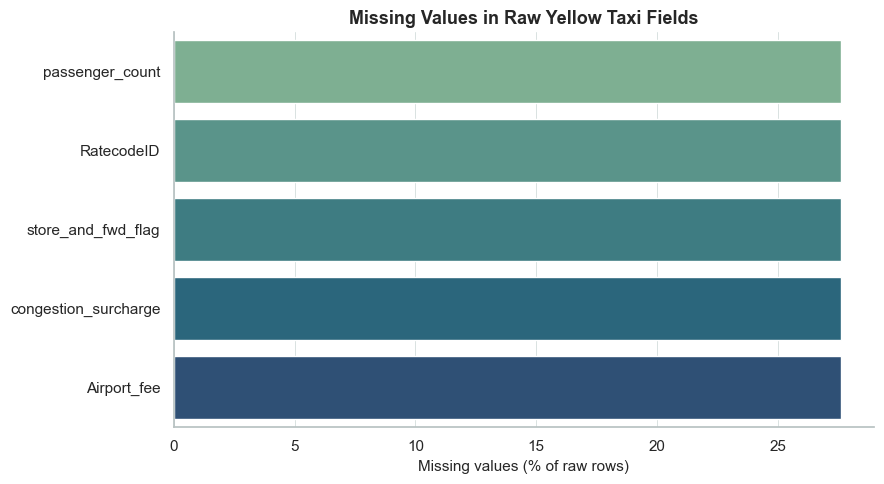

In [24]:
# 3.2 Schema and Missing Values

schema_summary = pd.DataFrame({
    "column": raw_df.columns,
    "dtype": raw_df.dtypes.astype(str).values,
    "missing_count": raw_df.isna().sum().values,
    "missing_percent": (raw_df.isna().mean().values * 100).round(2)
})

display(schema_summary)

missing_plot_df = schema_summary[schema_summary["missing_count"] > 0].sort_values(
    "missing_percent", ascending=False
)
if not missing_plot_df.empty:
    plt.figure(figsize=(9, 5))
    ax = sns.barplot(
        data=missing_plot_df,
        x="missing_percent",
        y="column",
        palette="crest",
    )
    ax.set_title("Missing Values in Raw Yellow Taxi Fields")
    ax.set_xlabel("Missing values (% of raw rows)")
    ax.set_ylabel("")
    sns.despine()
    plt.tight_layout()
    plt.show()

### Schema Interpretation

The raw data contains the essential fields needed for this project: pickup and drop-off datetimes, pickup and drop-off location IDs, passenger count, trip distance, fare amount, total amount, and payment-related fields. The timestamp columns are correctly loaded as datetime values, and the location identifiers are available for every raw row, which is critical for route construction.

The most visible schema issue is missingness in several optional or vendor-dependent fields. `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, and `Airport_fee` each have about 27.6% missing values. Because passenger count is useful but not central to defining route movement, this notebook keeps it as a modelling feature after filtering only clearly invalid zero-or-missing passenger values where appropriate. The route definition itself relies on pickup/drop-off IDs and timestamps, which are complete in the raw data.


In [25]:
# 3.3 Required Column Check

required_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
    "passenger_count",
    "fare_amount",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "payment_type",
    "RatecodeID"
]

missing_required_columns = [
    col for col in required_columns if col not in raw_df.columns]

if missing_required_columns:
    print("Missing required columns:", missing_required_columns)
else:
    print("All required columns are available.")

All required columns are available.


# 4. Initial Data Validation and Quality Checks

Operational taxi datasets can include impossible or implausible records caused by meter errors, data capture issues, refunds, cancellations, or post-processing anomalies. This section quantifies those issues before applying a reproducible cleaning function.


In [26]:
# 4.1 Create Validation Fields

validation_columns = [
    "tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
    "fare_amount", "total_amount", "PULocationID", "DOLocationID",
    "passenger_count",
]
validation_df = raw_df[validation_columns].copy()

validation_df["trip_duration_min"] = (
    validation_df["tpep_dropoff_datetime"] -
    validation_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

duration_hours = validation_df["trip_duration_min"] / 60
validation_df["avg_speed_mph"] = np.where(
    duration_hours > 0,
    validation_df["trip_distance"] / duration_hours,
    np.nan,
)

validation_df[["trip_duration_min", "avg_speed_mph"]].describe()

,trip_duration_min,avg_speed_mph
count,1.107721e+07,1.094240e+07
mean,1.742670e+01,2.301603e+01
std,2.508609e+01,3.421385e+03
min,-1.866667e+02,0.000000e+00
25%,8.150000e+00,6.634678e+00
50%,1.353333e+01,9.120000e+00
75%,2.153333e+01,1.268293e+01
max,9.265150e+03,4.816615e+06


In [27]:
# 4.2 Data Quality Summary Table
quality_checks = {
    "total_rows": len(validation_df),
    "pickup_outside_selected_scope": int(((validation_df["tpep_pickup_datetime"] < SCOPE_START) | (validation_df["tpep_pickup_datetime"] >= SCOPE_END)).sum()),
    "non_positive_duration": int((validation_df["trip_duration_min"] <= 0).sum()),
    "duration_over_180_min": int((validation_df["trip_duration_min"] > 180).sum()),
    "non_positive_distance": int((validation_df["trip_distance"] <= 0).sum()),
    "distance_over_100_miles": int((validation_df["trip_distance"] > 100).sum()),
    "negative_fare": int((validation_df["fare_amount"] < 0).sum()),
    "negative_total_amount": int((validation_df["total_amount"] < 0).sum()),
    "missing_pickup_zone": int(validation_df["PULocationID"].isna().sum()),
    "missing_dropoff_zone": int(validation_df["DOLocationID"].isna().sum()),
    "duplicate_rows": int(validation_df.duplicated().sum()),
    "unrealistic_speed_over_80mph": int((validation_df["avg_speed_mph"] > 80).sum()),
    "passenger_count_zero_or_missing": int(((validation_df["passenger_count"] <= 0) | (validation_df["passenger_count"].isna())).sum())
}
quality_summary = pd.DataFrame.from_dict(
    quality_checks, orient="index", columns=["count"])
quality_summary["percent_of_raw"] = (
    quality_summary["count"] / len(validation_df) * 100).round(2)
display(quality_summary.style.format(
    {"count": "{:,}", "percent_of_raw": "{:.2f}%"}).background_gradient(cmap="rocket_r"))

,count,percent_of_raw
total_rows,"11,077,206",100.00%
pickup_outside_selected_scope,10,0.00%
non_positive_duration,"134,801",1.22%
duration_over_180_min,"4,464",0.04%
non_positive_distance,"370,198",3.34%
distance_over_100_miles,495,0.00%
negative_fare,"86,908",0.78%
negative_total_amount,"88,580",0.80%
missing_pickup_zone,0,0.00%
missing_dropoff_zone,0,0.00%


### Data Quality Interpretation

The raw dataset contains 11,077,206 records. The file-level timestamp check shows that the selected monthly files contain a small number of pickup times outside the intended Jan-Mar 2026 analysis window, so the cleaning function applies an explicit pickup-date scope filter. The largest quality concern is passenger-count reliability: 3,097,761 records have zero or missing passenger counts, which is about 28% of the raw data. This does not invalidate route analysis because zone movement and timestamps remain available, but it means passenger count should be treated cautiously as a model feature.

Several errors directly affect modelling targets and therefore require filtering. There are non-positive-duration trips, non-positive-distance trips, negative fares, negative total amounts, and records with speeds over 80 mph. These cases can distort duration, speed, fare-per-mile, and route reliability metrics. The cleaning strategy removes these implausible records so the downstream route scores and prediction targets represent normal completed trips. Passenger-count zero values are retained for route analysis, then removed from modelling rows where passenger count is used as a predictor.


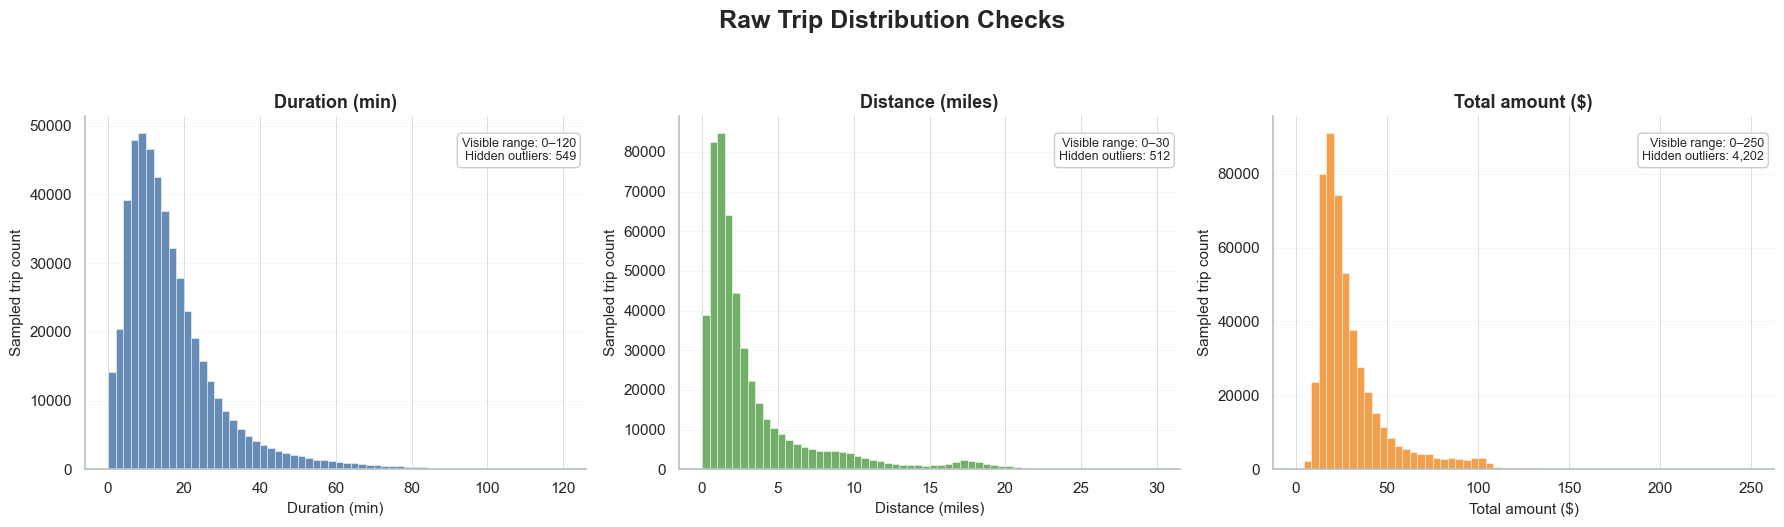

In [28]:
# 4.3 Visualise Raw Duration, Distance, and Fare Distributions

plot_df = validation_df.sample(
    n=min(500_000, len(validation_df)),
    random_state=42
)

plot_specs = [
    ("trip_duration_min", "Duration (min)", 0, 120, "#4C78A8"),
    ("trip_distance", "Distance (miles)", 0, 30, "#59A14F"),
    ("total_amount", "Total amount ($)", 0, 250, "#F28E2B"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fig.suptitle(
    "Raw Trip Distribution Checks",
    fontsize=18,
    fontweight="bold",
    y=1.05
)

for ax, (column, label, lower, upper, color) in zip(axes, plot_specs):
    values = (
        plot_df[column]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    visible_values = values[(values >= lower) & (values <= upper)]
    hidden_count = len(values) - len(visible_values)

    ax.hist(
        visible_values,
        bins=60,
        color=color,
        alpha=0.85,
        edgecolor="white",
        linewidth=0.4
    )

    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel("Sampled trip count", fontsize=11)

    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    ax.text(
        0.98,
        0.94,
        f"Visible range: {lower}–{upper}\nHidden outliers: {hidden_count:,}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.35",
                  facecolor="white", edgecolor="#cccccc")
    )

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

del plot_df
del validation_df

# 5. Data Wrangling and Cleaning Pipeline

The cleaning pipeline converts raw trip records into an analysis-ready dataset. It removes records that would make travel-time or fare modelling unreliable, while preserving the normal operating range of completed taxi trips.


In [29]:
# 5.1 Cleaning Function

def clean_yellow_taxi_data(df):
    trip_duration_min = (
        df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
    ).dt.total_seconds() / 60

    duration_hours = trip_duration_min / 60
    avg_speed_mph = pd.Series(
        np.where(
            duration_hours > 0,
            df["trip_distance"] / duration_hours,
            np.nan,
        ),
        index=df.index,
        dtype="float64",
    )

    before = len(df)

    valid_mask = (
        (trip_duration_min > 0) &
        (trip_duration_min <= 180) &
        (df["tpep_pickup_datetime"] >= SCOPE_START) &
        (df["tpep_pickup_datetime"] < SCOPE_END) &
        (df["trip_distance"] > 0) &
        (df["trip_distance"] <= 100) &
        (avg_speed_mph > 0) &
        (avg_speed_mph <= 80) &
        (df["fare_amount"] >= 0) &
        (df["total_amount"] >= 0) &
        (df["PULocationID"].notna()) &
        (df["DOLocationID"].notna())
    )

    cleaned = df.loc[valid_mask].copy()
    cleaned["trip_duration_min"] = trip_duration_min.loc[cleaned.index].to_numpy()
    cleaned["avg_speed_mph"] = avg_speed_mph.loc[cleaned.index].to_numpy()

    cleaned = cleaned.drop_duplicates()

    after = len(cleaned)
    print(f"Rows before cleaning: {before:,}")
    print(f"Rows after cleaning: {after:,}")
    print(f"Rows removed: {before - after:,}")
    print(f"Percentage removed: {((before - after) / before) * 100:.2f}%")

    return cleaned


clean_df = clean_yellow_taxi_data(raw_df)
clean_df.head()

Rows before cleaning: 11,077,206
Rows after cleaning: 10,487,427
Rows removed: 589,779
Percentage removed: 5.32%


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,avg_speed_mph
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00,5.550000,10.486486
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75,5.716667,9.446064
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75,8.883333,9.455910
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75,42.800000,7.822430
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75,13.500000,9.600000


In [30]:
# 5.2 Cleaning Summary Table

cleaning_summary = pd.DataFrame({
    "stage": ["Raw records", "Cleaned records", "Removed records"],
    "rows": [len(raw_df), len(clean_df), len(raw_df) - len(clean_df)]
})

cleaning_summary

,stage,rows
0,Raw records,11077206
1,Cleaned records,10487427
2,Removed records,589779


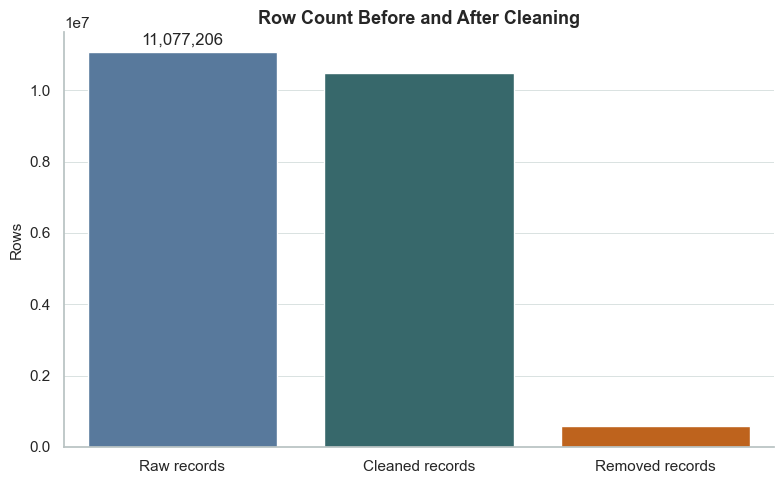

In [31]:
# 5.3 Visualise Cleaning Impact
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=cleaning_summary, x="stage", y="rows",
                 palette=["#4c78a8", "#2f6f73", "#d95f02"])
ax.set_title("Row Count Before and After Cleaning")
ax.set_xlabel("")
ax.set_ylabel("Rows")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)  # type: ignore
sns.despine()
plt.tight_layout()
plt.show()

### Cleaning Impact Interpretation

The cleaning pipeline reduces the dataset from 11,077,206 raw records to 10,487,427 cleaned records, removing 589,779 rows or 5.32% of the original data. This is a meaningful but not excessive reduction: the majority of the operational dataset is retained, while records with impossible duration, impossible distance, negative payment values, out-of-scope pickup times, and extreme speeds are excluded.

Passenger-count zero values are not removed at this stage because many 2026 rows have usable route, timestamp, distance, and payment fields even when passenger metadata is missing or coded as zero. Those records still contribute to route-hour demand and route relevance. Passenger count is filtered later only in modelling datasets that use it as an input feature.


# 6. Taxi Zone Metadata Integration

Numeric pickup and drop-off location IDs are joined to taxi-zone names, boroughs, and service-zone labels. This turns the model-ready data into an interpretable route-intelligence dataset.


In [32]:
# 6.1 Load Taxi Zone Lookup Table

zones = pd.read_csv(ZONE_LOOKUP_PATH)
zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [33]:
# 6.2 Join Pickup and Drop-off Zone Metadata

pickup_zones = zones.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "pickup_borough",
    "Zone": "pickup_zone",
    "service_zone": "pickup_service_zone"
})

dropoff_zones = zones.rename(columns={
    "LocationID": "DOLocationID",
    "Borough": "dropoff_borough",
    "Zone": "dropoff_zone",
    "service_zone": "dropoff_service_zone"
})

route_df = clean_df.merge(
    pickup_zones[["PULocationID", "pickup_borough",
                  "pickup_zone", "pickup_service_zone"]],
    on="PULocationID",
    how="left"
).merge(
    dropoff_zones[["DOLocationID", "dropoff_borough",
                   "dropoff_zone", "dropoff_service_zone"]],
    on="DOLocationID",
    how="left"
)

route_df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,avg_speed_mph,pickup_borough,pickup_zone,pickup_service_zone,dropoff_borough,dropoff_zone,dropoff_service_zone
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00,5.550000,10.486486,Manhattan,Upper West Side South,Yellow Zone,Manhattan,Upper West Side North,Yellow Zone
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75,5.716667,9.446064,Manhattan,Midtown North,Yellow Zone,Manhattan,Midtown East,Yellow Zone
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75,8.883333,9.455910,Manhattan,Central Park,Yellow Zone,Manhattan,Upper East Side South,Yellow Zone
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75,42.800000,7.822430,Manhattan,Lincoln Square East,Yellow Zone,Manhattan,Seaport,Yellow Zone
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75,13.500000,9.600000,Manhattan,Financial District South,Yellow Zone,Manhattan,Little Italy/NoLiTa,Yellow Zone


In [34]:
# 6.3 Check Metadata Join Quality

zone_join_quality = {
    "rows_after_join": len(route_df),
    "missing_pickup_zone_name": int(route_df["pickup_zone"].isna().sum()),
    "missing_dropoff_zone_name": int(route_df["dropoff_zone"].isna().sum()),
    "unique_pickup_zones": route_df["PULocationID"].nunique(),
    "unique_dropoff_zones": route_df["DOLocationID"].nunique()
}

pd.DataFrame.from_dict(zone_join_quality, orient="index", columns=["value"])

,value
rows_after_join,10487427
missing_pickup_zone_name,11684
missing_dropoff_zone_name,14489
unique_pickup_zones,262
unique_dropoff_zones,261


### Zone Join Interpretation

The taxi-zone lookup join is successful for nearly all records. After cleaning, the joined route table contains 10,487,427 rows. Missing pickup-zone names occur in 11,684 rows and missing drop-off-zone names occur in 14,489 rows, which is roughly one tenth of one percent of the cleaned dataset in each case. This small amount of missing metadata is acceptable for route-level analysis because the numeric location IDs remain available.

The join adds substantial interpretability. Instead of reporting only route IDs such as `237_236`, the analysis can describe routes such as `Upper East Side South -> Upper East Side North`, compare borough movement, and identify whether trips remain within the same zone or cross borough boundaries.


# 7. Feature Engineering

Trip-level features are created for temporal demand, route identity, movement type, speed, price efficiency, and tipping behaviour. These features support descriptive route intelligence and sklearn model inputs.


In [35]:
# 7.1 Create Trip-Level Features

feature_df = route_df.copy()

# Temporal features
feature_df["pickup_date"] = feature_df["tpep_pickup_datetime"].dt.date
feature_df["pickup_hour"] = feature_df["tpep_pickup_datetime"].dt.hour
feature_df["pickup_day_of_week"] = feature_df["tpep_pickup_datetime"].dt.day_name()
feature_df["pickup_day_num"] = feature_df["tpep_pickup_datetime"].dt.dayofweek
feature_df["is_weekend"] = feature_df["pickup_day_num"].isin([
                                                             5, 6]).astype(int)

# Exact-zone route definition. Numeric IDs are retained for joins; labels are for display only.
feature_df["route_id"] = (
    feature_df["PULocationID"].astype(
        str) + "_" + feature_df["DOLocationID"].astype(str)
)

pickup_label = feature_df["pickup_zone"].fillna(
    "Unknown PU " + feature_df["PULocationID"].astype(str))
dropoff_label = feature_df["dropoff_zone"].fillna(
    "Unknown DO " + feature_df["DOLocationID"].astype(str))
feature_df["route_label"] = pickup_label + " -> " + dropoff_label

feature_df["same_zone_trip"] = (
    feature_df["PULocationID"] == feature_df["DOLocationID"]
).astype(int)

feature_df["inter_borough_trip"] = (
    feature_df["pickup_borough"] != feature_df["dropoff_borough"]
).astype(int)

# Fare and efficiency features
feature_df["fare_per_mile"] = feature_df["fare_amount"] / \
    feature_df["trip_distance"]
feature_df["total_per_mile"] = feature_df["total_amount"] / \
    feature_df["trip_distance"]
feature_df["tip_percentage"] = np.where(
    feature_df["fare_amount"] > 0,
    feature_df["tip_amount"] / feature_df["fare_amount"],
    np.nan,
)

display(feature_df.head())

del raw_df, clean_df, route_df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,avg_speed_mph,pickup_borough,pickup_zone,pickup_service_zone,dropoff_borough,dropoff_zone,dropoff_service_zone,pickup_date,pickup_hour,pickup_day_of_week,pickup_day_num,is_weekend,route_id,route_label,same_zone_trip,inter_borough_trip,fare_per_mile,total_per_mile,tip_percentage
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00,5.550000,10.486486,Manhattan,Upper West Side South,Yellow Zone,Manhattan,Upper West Side North,Yellow Zone,2026-01-01,0,Thursday,3,0,239_238,Upper West Side South -> Upper West Side North,0,0,7.422680,16.350515,0.508333
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75,5.716667,9.446064,Manhattan,Midtown North,Yellow Zone,Manhattan,Midtown East,Yellow Zone,2026-01-01,0,Thursday,3,0,163_162,Midtown North -> Midtown East,0,0,8.777778,15.166667,0.000000
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75,8.883333,9.455910,Manhattan,Central Park,Yellow Zone,Manhattan,Upper East Side South,Yellow Zone,2026-01-01,0,Thursday,3,0,43_237,Central Park -> Upper East Side South,0,0,7.642857,13.535714,0.233645
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75,42.800000,7.822430,Manhattan,Lincoln Square East,Yellow Zone,Manhattan,Seaport,Yellow Zone,2026-01-01,0,Thursday,3,0,142_209,Lincoln Square East -> Seaport,0,0,6.935484,9.956989,0.287080
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75,13.500000,9.600000,Manhattan,Financial District South,Yellow Zone,Manhattan,Little Italy/NoLiTa,Yellow Zone,2026-01-01,0,Thursday,3,0,88_144,Financial District South -> Little Italy/NoLiTa,0,0,6.250000,10.694444,0.285185


In [36]:
# 7.2 Feature Summary

feature_columns = [
    "pickup_date", "pickup_hour", "pickup_day_of_week", "pickup_day_num", "is_weekend",
    "route_id", "route_label", "same_zone_trip", "inter_borough_trip",
    "trip_duration_min", "avg_speed_mph", "fare_per_mile", "total_per_mile", "tip_percentage"
]

feature_df[feature_columns].describe(include="all")

,pickup_date,pickup_hour,pickup_day_of_week,pickup_day_num,is_weekend,route_id,route_label,same_zone_trip,inter_borough_trip,trip_duration_min,avg_speed_mph,fare_per_mile,total_per_mile,tip_percentage
count,10487427,1.048743e+07,10487427,1.048743e+07,1.048743e+07,10487427,10487427,1.048743e+07,1.048743e+07,1.048743e+07,1.048743e+07,1.048743e+07,1.048743e+07,1.048289e+07
unique,90,NaN,7,NaN,NaN,47894,47735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2026-03-12,NaN,Saturday,NaN,NaN,237_236,Upper East Side South -> Upper East Side North,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,150022,NaN,1726089,NaN,NaN,68482,68482,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1.410151e+01,NaN,3.115524e+00,2.936938e-01,NaN,NaN,3.940986e-02,1.516573e-01,1.740878e+01,1.090962e+01,2.786856e+01,3.693305e+01,1.649594e-01
std,NaN,6.055979e+00,NaN,1.917536e+00,4.554534e-01,NaN,NaN,1.945680e-01,3.586884e-01,1.410290e+01,6.419945e+00,2.710356e+02,3.172896e+02,6.339529e-01
min,NaN,0.000000e+00,NaN,0.000000e+00,0.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,1.666667e-02,4.999306e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,NaN,1.000000e+01,NaN,1.000000e+00,0.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,8.400000e+00,6.905028e+00,5.821429e+00,8.254386e+00,0.000000e+00
50%,NaN,1.500000e+01,NaN,3.000000e+00,0.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,1.370000e+01,9.296360e+00,7.662338e+00,1.205584e+01,1.778309e-01
75%,NaN,1.900000e+01,NaN,5.000000e+00,1.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,2.168333e+01,1.285714e+01,1.014085e+01,1.705556e+01,2.860215e-01


### Engineered Feature Interpretation

The engineered features translate raw trip records into variables aligned with the business problem. `pickup_hour`, `pickup_day_of_week`, `pickup_day_num`, and `is_weekend` capture recurring demand cycles. `route_id` and `route_label` define the exact pickup-to-drop-off zone pair used for aggregation. `same_zone_trip` and `inter_borough_trip` add operational context about trip geography.

The derived performance fields also matter. `trip_duration_min` becomes the primary duration target, `avg_speed_mph` helps identify abnormal travel behaviour, `fare_per_mile` and `total_per_mile` support value interpretation, and `tip_percentage` provides a limited customer-payment proxy. The feature summary shows 47,894 unique route IDs and 90 pickup dates, which confirms a rich route-hour modelling space.


# 8. Exploratory Data Analysis

The EDA section examines demand timing, day-of-week variation, route recurrence, duration-distance relationships, and distribution shape. These findings motivate the route relevance score and the features used in the sklearn models.


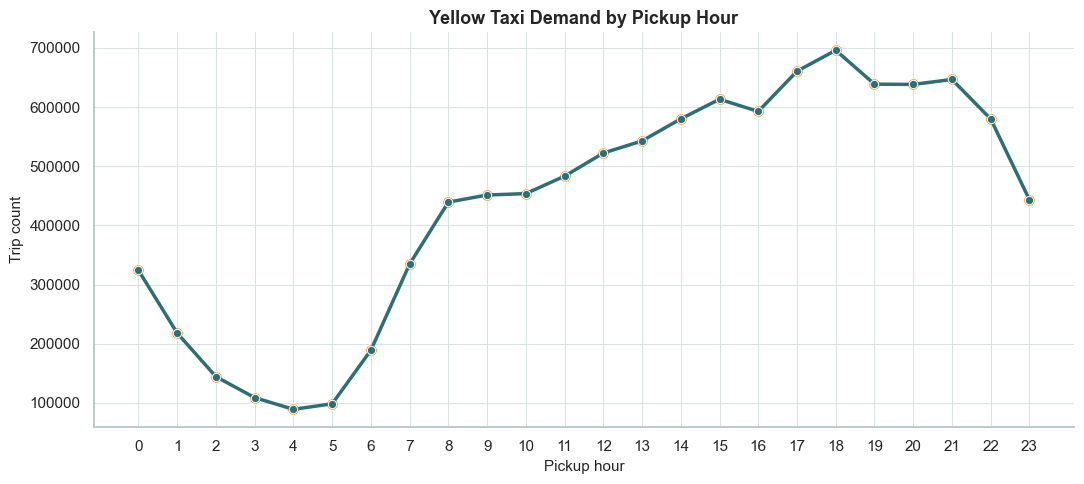

In [37]:
# 8.1 Trip Count by Hour
hour_counts = feature_df.groupby(
    "pickup_hour").size().reset_index(name="trip_count")
plt.figure(figsize=(11, 5))
ax = sns.lineplot(data=hour_counts, x="pickup_hour",
                  y="trip_count", marker="o", linewidth=2.5, color="#2f6f73")
sns.scatterplot(data=hour_counts, x="pickup_hour",
                y="trip_count", s=70, color="#f28e2b", ax=ax)
ax.set_title("Yellow Taxi Demand by Pickup Hour")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Trip count")
ax.set_xticks(range(0, 24))
sns.despine()
plt.tight_layout()
plt.show()

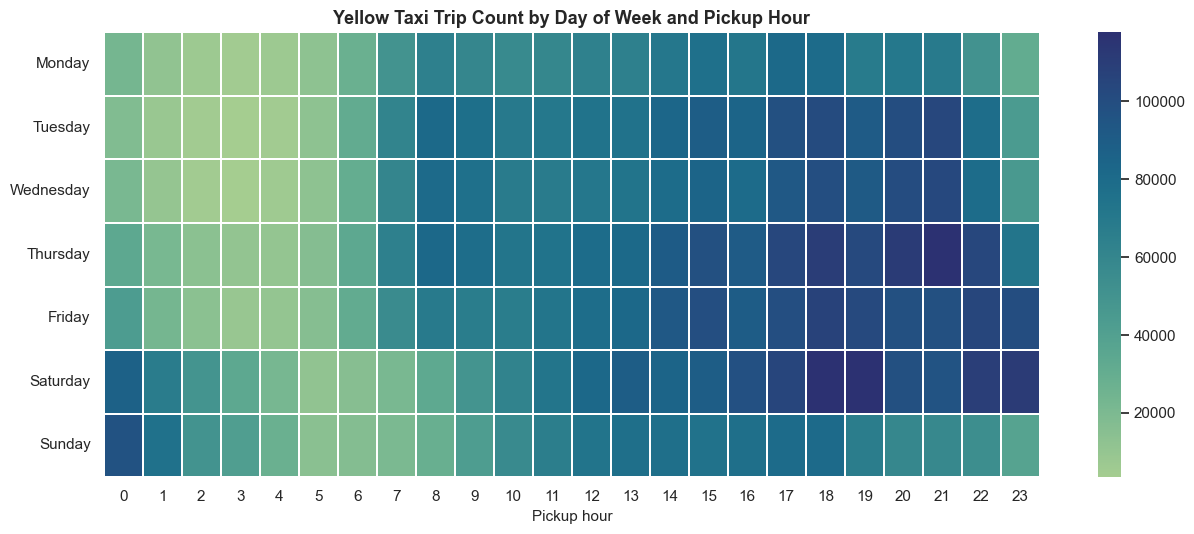

In [38]:
# 8.2 Trip Count Heatmap by Day and Hour
day_order = ["Monday", "Tuesday", "Wednesday",
             "Thursday", "Friday", "Saturday", "Sunday"]
heatmap_df = (
    feature_df.groupby(["pickup_day_of_week", "pickup_hour"])
    .size()
    .reset_index(name="trip_count")
)
heatmap_pivot = (
    heatmap_df.pivot(index="pickup_day_of_week",
                     columns="pickup_hour", values="trip_count")
    .reindex(day_order)
)
plt.figure(figsize=(13, 5.5))
ax = sns.heatmap(heatmap_pivot, cmap="crest",
                 linewidths=0.2, linecolor="white")
ax.set_title("Yellow Taxi Trip Count by Day of Week and Pickup Hour")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

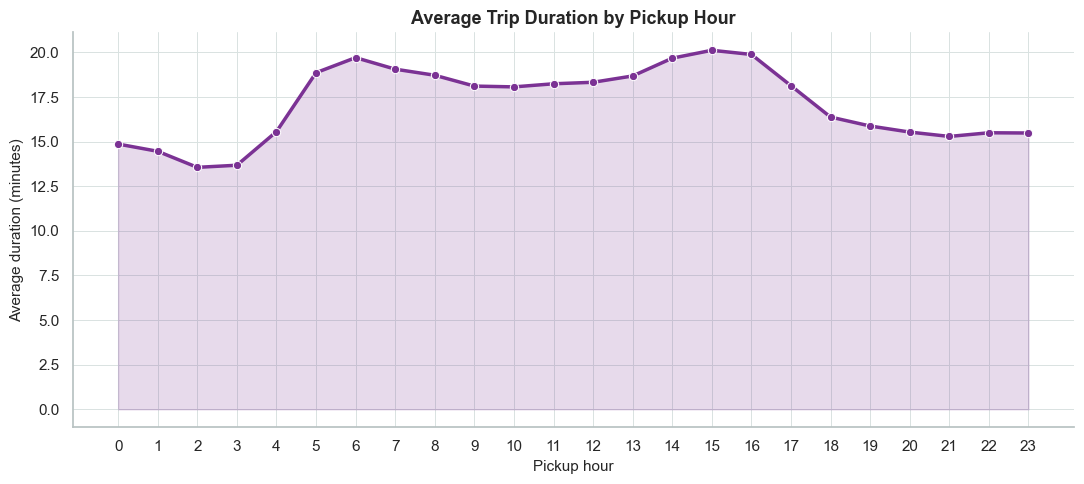

In [39]:
# 8.3 Average Duration by Pickup Hour
avg_duration_hour = feature_df.groupby("pickup_hour", as_index=False)[
    "trip_duration_min"].mean()
plt.figure(figsize=(11, 5))
ax = sns.lineplot(data=avg_duration_hour, x="pickup_hour",
                  y="trip_duration_min", marker="o", linewidth=2.5, color="#7b3294")
ax.fill_between(avg_duration_hour["pickup_hour"],
                avg_duration_hour["trip_duration_min"], alpha=0.18, color="#7b3294")
ax.set_title("Average Trip Duration by Pickup Hour")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Average duration (minutes)")
ax.set_xticks(range(0, 24))
sns.despine()
plt.tight_layout()
plt.show()

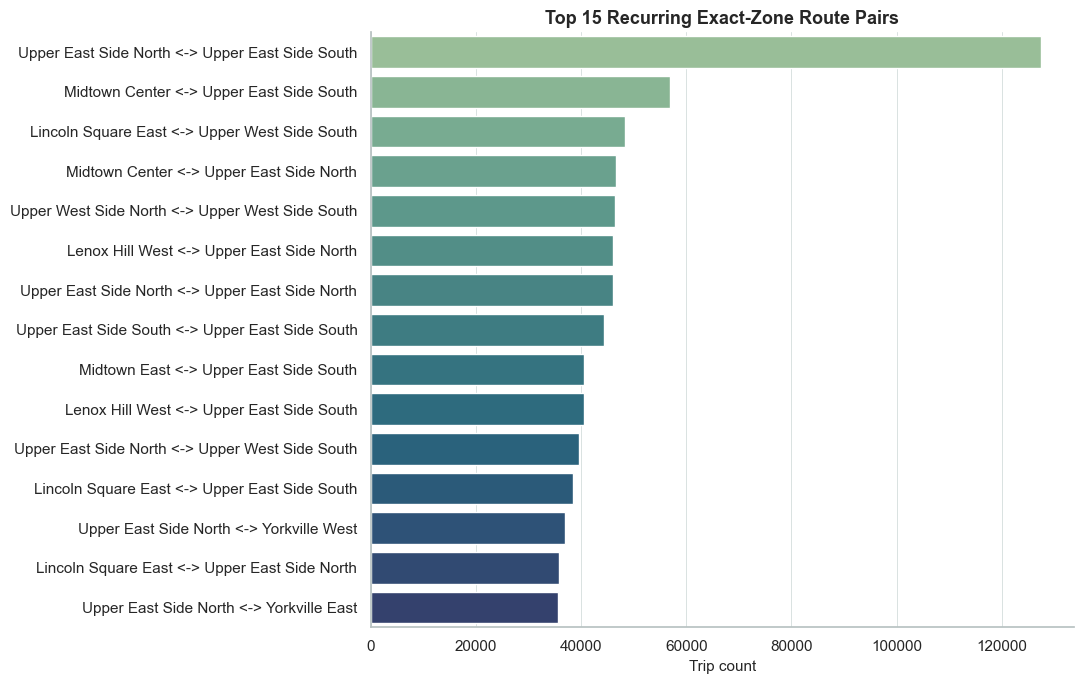

In [42]:
# 8.4 Top Recurring Exact-Zone Route Pairs

route_a = feature_df["pickup_zone"].astype(str)
route_b = feature_df["dropoff_zone"].astype(str)

feature_df["route_pair_label"] = (
    np.minimum(route_a, route_b) + " <-> " + np.maximum(route_a, route_b)
)

top_routes = (
    feature_df["route_pair_label"]
    .value_counts()
    .head(15)
    .reset_index()
)

top_routes.columns = ["route_pair_label", "trip_count"]

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=top_routes,
    x="trip_count",
    y="route_pair_label",
    palette="crest"
)

ax.set_title("Top 15 Recurring Exact-Zone Route Pairs")
ax.set_xlabel("Trip count")
ax.set_ylabel("")

sns.despine()
plt.tight_layout()
plt.show()

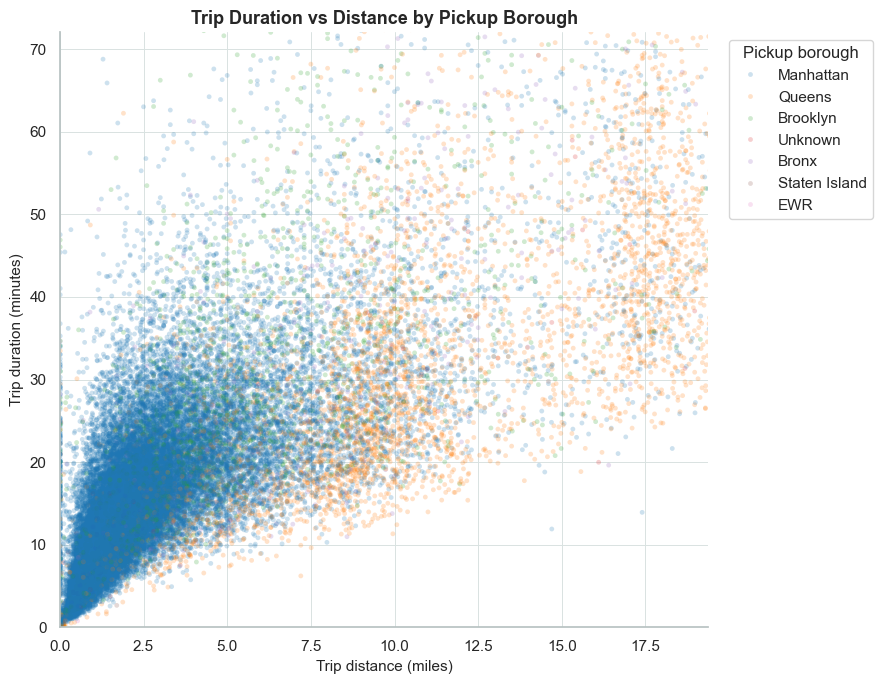

In [43]:
# 8.5 Duration vs Distance Density Scatter Plot
sample_df = feature_df.sample(min(50000, len(feature_df)), random_state=42)
plt.figure(figsize=(9, 7))
ax = sns.scatterplot(
    data=sample_df,
    x="trip_distance",
    y="trip_duration_min",
    hue="pickup_borough",
    alpha=0.22,
    s=12,
    palette="tab10",
    linewidth=0,
)
ax.set_xlim(0, sample_df["trip_distance"].quantile(0.99))
ax.set_ylim(0, sample_df["trip_duration_min"].quantile(0.99))
ax.set_title("Trip Duration vs Distance by Pickup Borough")
ax.set_xlabel("Trip distance (miles)")
ax.set_ylabel("Trip duration (minutes)")
ax.legend(title="Pickup borough", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

### EDA Interpretation

The EDA shows that demand is strongly time-dependent rather than evenly distributed across the day. Pickup hour is therefore a necessary feature for both route scoring and prediction. The day-hour heatmap makes this pattern clearer than a single daily total because it shows when demand concentrates within each day.

Route recurrence is concentrated in a small set of high-volume Manhattan and airport-related corridors. The most frequent route in the engineered data is `Upper East Side South -> Upper East Side North`, appearing 68,482 times at trip level. This supports the route-hour aggregation approach: exact zone pairs repeat often enough to identify practical recurring taxi corridors, but the full route space remains broad with nearly 48,000 unique route IDs.

The duration-distance scatter confirms a positive relationship between trip distance and duration, but the relationship is not perfectly linear. Short trips can still take a long time in congested areas, and longer trips can vary depending on route type, airport movement, borough, and time of day. This non-linearity is the main reason the final modelling section compares a simple baseline with a stronger HistGradientBoosting model.


# 9. Route-Level Aggregation

Trip-level records are aggregated into route-hour records using day of week, pickup hour, and exact pickup-to-drop-off zone pair. This creates the level of detail needed for route relevance scoring.


In [44]:
# 9.1 Build Route-Hour Aggregation

route_hour_counts = (
    feature_df
    .groupby([
        "pickup_day_of_week", "pickup_day_num", "pickup_hour",
        "PULocationID", "DOLocationID", "route_id", "route_label"
    ])
    .agg(
        trip_count=("route_id", "size"),
        avg_duration_min=("trip_duration_min", "mean"),
        median_duration_min=("trip_duration_min", "median"),
        std_duration_min=("trip_duration_min", "std"),
        avg_total_amount=("total_amount", "mean"),
        median_total_amount=("total_amount", "median"),
        avg_fare_amount=("fare_amount", "mean"),
        avg_distance=("trip_distance", "mean"),
        avg_speed_mph=("avg_speed_mph", "mean")
    )
    .reset_index()
)

route_hour_counts = route_hour_counts.sort_values(
    ["pickup_day_num", "pickup_hour", "trip_count"],
    ascending=[True, True, False]
)

route_hour_counts.head(20)

,pickup_day_of_week,pickup_day_num,pickup_hour,PULocationID,DOLocationID,route_id,route_label,trip_count,avg_duration_min,median_duration_min,std_duration_min,avg_total_amount,median_total_amount,avg_fare_amount,avg_distance,avg_speed_mph
202328,Monday,0,0,132,93,132_93,JFK Airport -> Flushing Meadows-Corona Park,183,12.321767,11.750000,4.075899,35.956120,35.500,31.536612,8.005464,40.506805
202468,Monday,0,0,132,265,132_265,JFK Airport -> Outside of NYC,171,30.470175,25.850000,16.046709,110.299357,77.650,92.280702,18.625263,34.877118
205562,Monday,0,0,246,48,246_48,West Chelsea/Hudson Yards -> Clinton East,58,6.002586,5.658333,2.026144,17.150345,16.990,9.157759,1.272931,13.282935
202750,Monday,0,0,138,236,138_236,LaGuardia Airport -> Upper East Side North,56,18.118750,17.558333,3.669783,61.290536,60.630,35.271250,8.432857,28.593595
202295,Monday,0,0,132,56,132_56,JFK Airport -> Corona,55,14.759091,13.250000,6.400229,39.577818,39.450,34.920000,9.189273,39.972682
202317,Monday,0,0,132,82,132_82,JFK Airport -> Elmhurst,55,15.947576,14.466667,4.726149,44.809455,44.350,39.298182,10.372545,40.986094
202772,Monday,0,0,138,263,138_263,LaGuardia Airport -> Yorkville West,55,15.117273,14.850000,2.103573,59.177455,59.900,32.552727,8.203636,32.974897
202257,Monday,0,0,132,10,132_10,JFK Airport -> Baisley Park,53,8.760377,8.300000,3.158536,22.362830,21.250,16.247170,3.623019,26.373776
205683,Monday,0,0,249,79,249_79,West Village -> East Village,53,7.586164,7.533333,1.845550,18.980566,17.750,11.729623,1.218491,9.840712
202771,Monday,0,0,138,262,138_262,LaGuardia Airport -> Yorkville East,52,15.356090,14.466667,3.518877,61.308462,61.000,33.903846,8.194808,32.891170


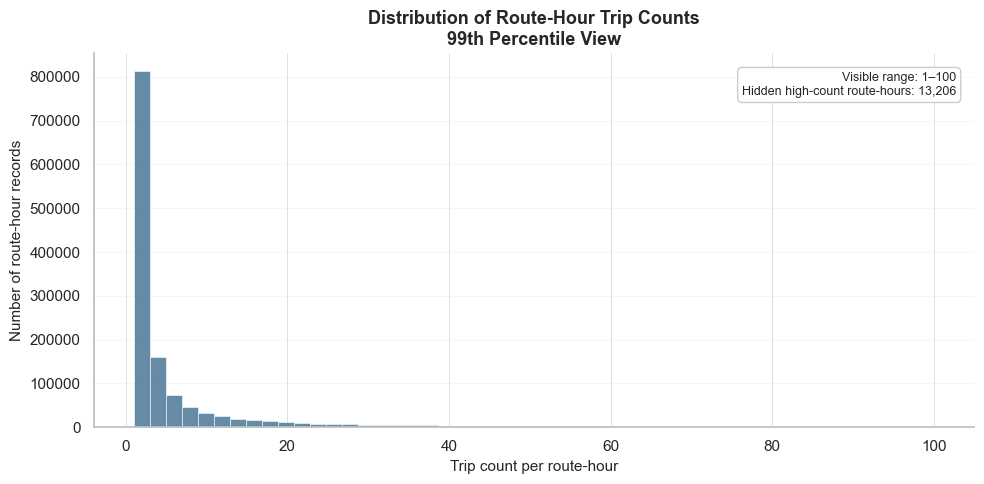

In [46]:
# 9.2 Route Frequency Distribution

trip_counts = route_hour_counts["trip_count"].dropna()

upper_limit = trip_counts.quantile(0.99)
visible_counts = trip_counts[trip_counts <= upper_limit]
hidden_count = (trip_counts > upper_limit).sum()

plt.figure(figsize=(10, 5))

ax = sns.histplot(
    visible_counts,
    bins=50,
    color="#33658a",
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Distribution of Route-Hour Trip Counts\n99th Percentile View")
ax.set_xlabel("Trip count per route-hour")
ax.set_ylabel("Number of route-hour records")

ax.text(
    0.98,
    0.95,
    f"Visible range: 1–{upper_limit:.0f}\nHidden high-count route-hours: {hidden_count:,}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.35",
              facecolor="white", edgecolor="#cccccc")
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

### Route-Hour Table Interpretation

The route-hour table reveals a highly fragmented long-tail demand pattern. There are many route-hour combinations with low trip counts and a smaller number of corridors with very high recurrence. This is expected for exact taxi-zone pairs because NYC contains many possible origin-destination combinations, but demand concentrates around dense Manhattan zones, airports, and major activity centres.

This finding supports the decision to avoid a hard binary target such as `important route` versus `not important route`. A continuous relevance score is more appropriate because route importance is gradual: frequency, reliability, fare value, distance, and speed all contribute in different ways.


# 10. Route Relevance Scoring

Route relevance is calculated as a continuous score using route-hour frequency, duration reliability, and fare value. The score is designed for interpretation rather than as a hidden model target. The initial weights are frequency 0.45, fare value 0.25, and duration reliability 0.30, which prioritises repeated demand while still accounting for customer reliability and commercial value.


In [50]:
# 10.1 Create Route Relevance Score

scoring_df = route_hour_counts.copy()

# Fill missing standard deviations for route-hours with one observation
scoring_df["std_duration_min"] = scoring_df["std_duration_min"].fillna(
    scoring_df["std_duration_min"].median()
)

# Robust scaling helper:
# clips extreme values before min-max scaling so one outlier route does not dominate.


def robust_min_max_scale(series, lower_q=0.01, upper_q=0.99):
    series = series.replace([np.inf, -np.inf], np.nan)
    series = series.fillna(series.median())

    lower = series.quantile(lower_q)
    upper = series.quantile(upper_q)

    clipped = series.clip(lower=lower, upper=upper)

    min_val = clipped.min()
    max_val = clipped.max()

    if max_val == min_val:
        return pd.Series(0.0, index=series.index)

    return (clipped - min_val) / (max_val - min_val)


# Frequency score:
# log1p reduces the impact of extremely high-volume route-hours.
scoring_df["frequency_score"] = robust_min_max_scale(
    np.log1p(scoring_df["trip_count"])
)

# Fare score:
# clipped scaling prevents unusually expensive trips from dominating.
scoring_df["fare_score"] = robust_min_max_scale(
    scoring_df["avg_total_amount"]
)

# Reliability score:
# coefficient of variation is better than raw standard deviation because it
# measures variation relative to average duration.
scoring_df["duration_cv"] = (
    scoring_df["std_duration_min"] / scoring_df["avg_duration_min"]
).replace([np.inf, -np.inf], np.nan)

scoring_df["duration_cv"] = scoring_df["duration_cv"].fillna(
    scoring_df["duration_cv"].median()
)

scoring_df["duration_reliability_score"] = 1 - robust_min_max_scale(
    scoring_df["duration_cv"]
)

# Demand consistency score:
# measures how many distinct pickup dates the route-hour appeared on.
if "pickup_date" not in feature_df.columns:
    feature_df["pickup_date"] = feature_df["tpep_pickup_datetime"].dt.date

consistency_df = (
    feature_df.groupby([
        "pickup_day_num",
        "pickup_hour",
        "PULocationID",
        "DOLocationID"
    ])["pickup_date"]
    .nunique()
    .reset_index(name="active_days")
)

scoring_df = scoring_df.merge(
    consistency_df,
    on=["pickup_day_num", "pickup_hour", "PULocationID", "DOLocationID"],
    how="left"
)

scoring_df["active_days"] = scoring_df["active_days"].fillna(0)

scoring_df["consistency_score"] = robust_min_max_scale(
    scoring_df["active_days"]
)

# Adjustable weighted route score:
# balanced between demand, commercial value, reliability, and consistency.
scoring_df["route_relevance_score"] = (
    0.35 * scoring_df["frequency_score"] +
    0.20 * scoring_df["fare_score"] +
    0.25 * scoring_df["duration_reliability_score"] +
    0.20 * scoring_df["consistency_score"]
)

scoring_df = scoring_df.sort_values(
    "route_relevance_score",
    ascending=False
)

scoring_df[[
    "route_label",
    "pickup_day_of_week",
    "pickup_hour",
    "trip_count",
    "active_days",
    "avg_duration_min",
    "std_duration_min",
    "duration_cv",
    "avg_total_amount",
    "frequency_score",
    "fare_score",
    "duration_reliability_score",
    "consistency_score",
    "route_relevance_score"
]].head(20)

,route_label,pickup_day_of_week,pickup_hour,trip_count,active_days,avg_duration_min,std_duration_min,duration_cv,avg_total_amount,frequency_score,fare_score,duration_reliability_score,consistency_score,route_relevance_score
128267,JFK Airport -> Times Sq/Theatre District,Monday,18,154,13,48.630952,6.179457,0.127068,101.626494,1.000000,0.889537,0.881119,1.000000,0.948187
286594,JFK Airport -> Midtown Center,Tuesday,16,118,13,59.106497,8.784115,0.148615,104.130424,1.000000,0.914072,0.857903,1.000000,0.947290
286579,JFK Airport -> Midtown South,Tuesday,16,127,13,54.702362,8.253713,0.150884,103.825276,1.000000,0.911082,0.855458,1.000000,0.946081
286518,JFK Airport -> Times Sq/Theatre District,Tuesday,16,220,13,62.560000,8.902120,0.142297,101.024409,1.000000,0.883637,0.864710,1.000000,0.942905
311154,JFK Airport -> Times Sq/Theatre District,Tuesday,19,103,13,43.588997,6.917647,0.158702,101.846214,1.000000,0.891690,0.847035,1.000000,0.940097
319234,JFK Airport -> Times Sq/Theatre District,Tuesday,20,116,13,42.358046,5.439779,0.128424,97.408879,1.000000,0.848211,0.879659,1.000000,0.939557
812177,JFK Airport -> Times Sq/Theatre District,Friday,12,142,13,61.064789,6.910943,0.113174,95.102746,1.000000,0.825614,0.896090,1.000000,0.939145
689913,JFK Airport -> Times Sq/Theatre District,Thursday,20,121,13,44.187741,5.645000,0.127750,96.777851,1.000000,0.842028,0.880384,1.000000,0.938502
851286,JFK Airport -> Midtown Center,Friday,16,104,13,63.146474,10.013155,0.158570,100.924135,1.000000,0.882655,0.847176,1.000000,0.938325
294833,JFK Airport -> Times Sq/Theatre District,Tuesday,17,174,13,58.475766,9.424117,0.161163,100.465517,1.000000,0.878161,0.844383,1.000000,0.936728


In [51]:
# 10.2 Assign Adjustable Relevance Labels

thresholds = [0.00, 0.35, 0.55, 0.75, 1.00]

labels = [
    "Low relevance",
    "Moderate relevance",
    "High relevance",
    "Priority route"
]

scoring_df["route_relevance_label"] = pd.cut(
    scoring_df["route_relevance_score"],
    bins=thresholds,
    labels=labels,
    include_lowest=True
)

scoring_df[[
    "route_label",
    "pickup_day_of_week",
    "pickup_hour",
    "trip_count",
    "active_days",
    "avg_duration_min",
    "avg_total_amount",
    "route_relevance_score",
    "route_relevance_label"
]].head(20)

,route_label,pickup_day_of_week,pickup_hour,trip_count,active_days,avg_duration_min,avg_total_amount,route_relevance_score,route_relevance_label
128267,JFK Airport -> Times Sq/Theatre District,Monday,18,154,13,48.630952,101.626494,0.948187,Priority route
286594,JFK Airport -> Midtown Center,Tuesday,16,118,13,59.106497,104.130424,0.947290,Priority route
286579,JFK Airport -> Midtown South,Tuesday,16,127,13,54.702362,103.825276,0.946081,Priority route
286518,JFK Airport -> Times Sq/Theatre District,Tuesday,16,220,13,62.560000,101.024409,0.942905,Priority route
311154,JFK Airport -> Times Sq/Theatre District,Tuesday,19,103,13,43.588997,101.846214,0.940097,Priority route
319234,JFK Airport -> Times Sq/Theatre District,Tuesday,20,116,13,42.358046,97.408879,0.939557,Priority route
812177,JFK Airport -> Times Sq/Theatre District,Friday,12,142,13,61.064789,95.102746,0.939145,Priority route
689913,JFK Airport -> Times Sq/Theatre District,Thursday,20,121,13,44.187741,96.777851,0.938502,Priority route
851286,JFK Airport -> Midtown Center,Friday,16,104,13,63.146474,100.924135,0.938325,Priority route
294833,JFK Airport -> Times Sq/Theatre District,Tuesday,17,174,13,58.475766,100.465517,0.936728,Priority route


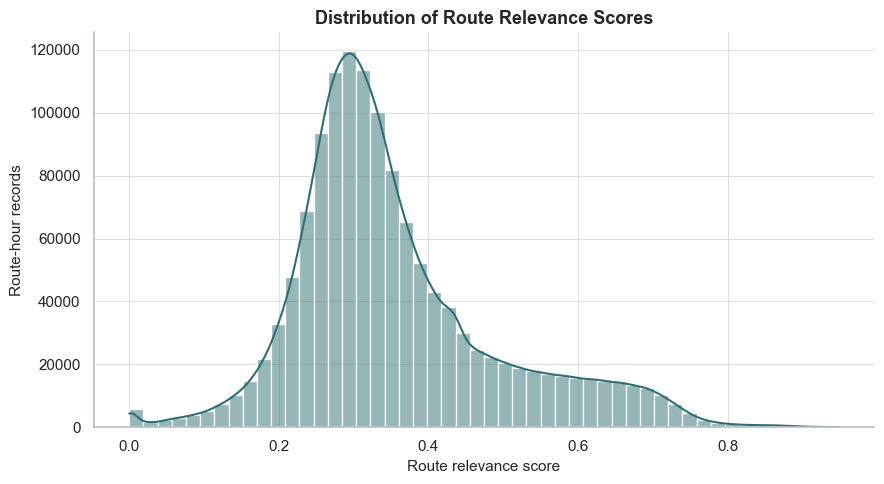

In [52]:
# 10.3 Visualise Route Relevance Score Distribution
plt.figure(figsize=(9, 5))
ax = sns.histplot(scoring_df["route_relevance_score"],
                  bins=50, kde=True, color="#2f6f73")
ax.set_title("Distribution of Route Relevance Scores")
ax.set_xlabel("Route relevance score")
ax.set_ylabel("Route-hour records")
sns.despine()
plt.tight_layout()
plt.show()

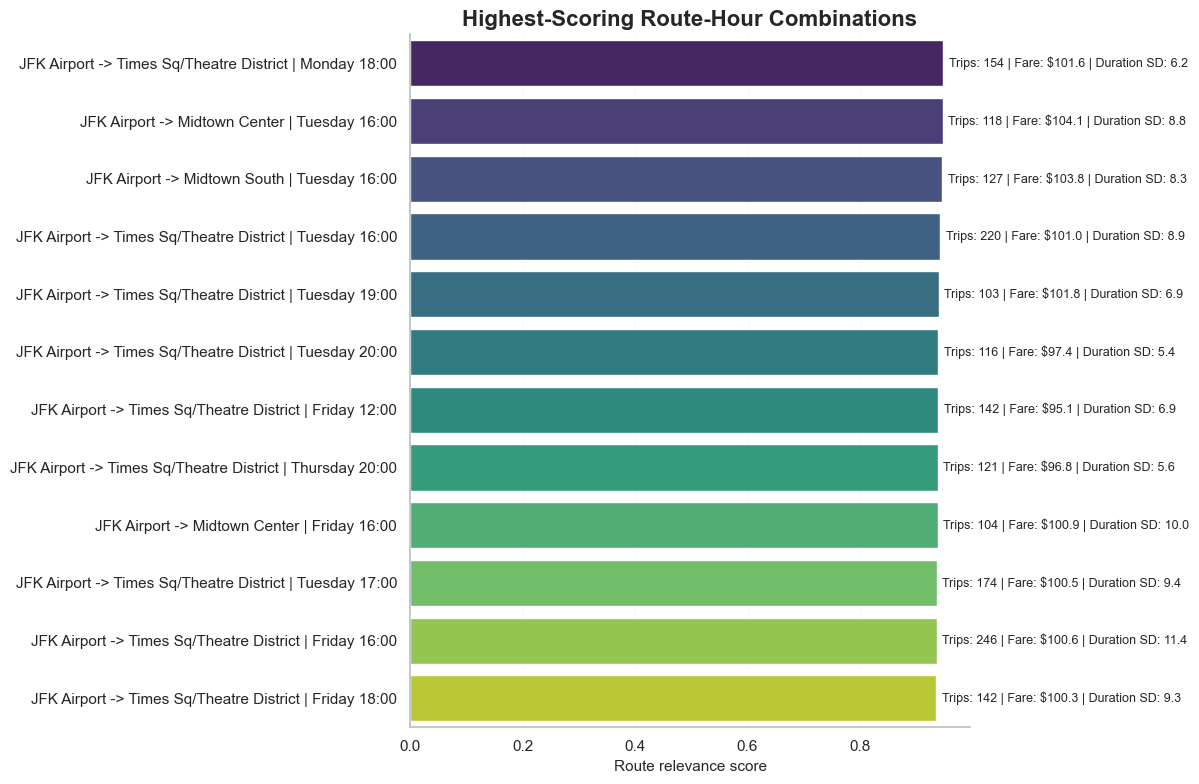

In [54]:
# 10.4 Top Priority Routes

top_priority_routes = (
    scoring_df[
        scoring_df["route_relevance_label"] == "Priority route"
    ]
    .head(12)
    .copy()
)

# Create compact readable labels
top_priority_routes["display_label"] = (
    top_priority_routes["route_label"]
    + " | "
    + top_priority_routes["pickup_day_of_week"]
    + " "
    + top_priority_routes["pickup_hour"].astype(str)
    + ":00"
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=top_priority_routes,
    x="route_relevance_score",
    y="display_label",
    palette="viridis"
)

ax.set_title(
    "Highest-Scoring Route-Hour Combinations",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Route relevance score")
ax.set_ylabel("")

# Annotate bars with supporting operational metrics
for i, row in enumerate(top_priority_routes.itertuples()):

    annotation = (
        f"Trips: {row.trip_count:,} | "
        f"Fare: ${row.avg_total_amount:.1f} | "
        f"Duration SD: {row.std_duration_min:.1f}"
    )

    ax.text(
        row.route_relevance_score + 0.01,
        i,
        annotation,
        va="center",
        fontsize=9
    )

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

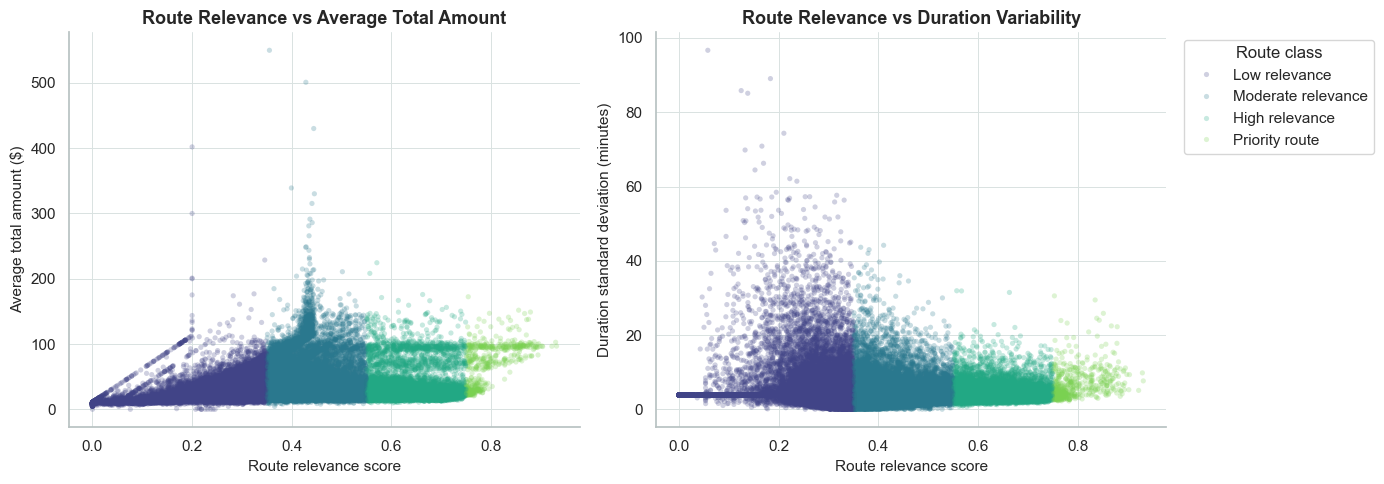

In [55]:
# 10.5 Route Relevance Trade-off Checks
plot_sample = scoring_df.sample(min(80000, len(scoring_df)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=plot_sample,
    x="route_relevance_score",
    y="avg_total_amount",
    hue="route_relevance_label",
    alpha=0.25,
    s=14,
    linewidth=0,
    palette="viridis",
    ax=axes[0],
    legend=False,
)
axes[0].set_title("Route Relevance vs Average Total Amount")
axes[0].set_xlabel("Route relevance score")
axes[0].set_ylabel("Average total amount ($)")

sns.scatterplot(
    data=plot_sample,
    x="route_relevance_score",
    y="std_duration_min",
    hue="route_relevance_label",
    alpha=0.25,
    s=14,
    linewidth=0,
    palette="viridis",
    ax=axes[1],
)
axes[1].set_title("Route Relevance vs Duration Variability")
axes[1].set_xlabel("Route relevance score")
axes[1].set_ylabel("Duration standard deviation (minutes)")
axes[1].legend(title="Route class", bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine()
plt.tight_layout()
plt.show()

In [87]:
zones_gdf = gpd.read_file("data/taxi_zones/taxi_zones.shp")
zones_gdf.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


In [ ]:
# 10.6 Load Taxi Zone Geometry for Route Relevance Mapping

ZONE_GEO_PATH = Path("data/taxi_zones/taxi_zones.shp")

if not ZONE_GEO_PATH.exists():
    raise FileNotFoundError(
        f"Taxi zone shapefile not found at: {ZONE_GEO_PATH}")

zones_gdf = gpd.read_file(ZONE_GEO_PATH)

# Standardise LocationID column name
if "LocationID" in zones_gdf.columns:
    pass
elif "location_id" in zones_gdf.columns:
    zones_gdf = zones_gdf.rename(columns={"location_id": "LocationID"})
elif "LocationID" not in zones_gdf.columns and "LocationID" not in zones_gdf.columns:
    raise ValueError(
        f"Could not find LocationID column. Available columns: {zones_gdf.columns.tolist()}"
    )

zones_gdf["LocationID"] = zones_gdf["LocationID"].astype(int)

# Convert geometry to WGS84 latitude/longitude for Folium
zones_gdf = zones_gdf.to_crs(epsg=4326)

# Use representative points instead of centroids so points stay inside taxi-zone polygons
zones_gdf["representative_point"] = zones_gdf.geometry.representative_point()
zones_gdf["lat"] = zones_gdf["representative_point"].y
zones_gdf["lon"] = zones_gdf["representative_point"].x

zone_centroids = zones_gdf[["LocationID", "lat", "lon"]].copy()

zone_centroids.head()

,LocationID,lat,lon
0,1,40.689515,-74.176778
1,2,40.625724,-73.826141
2,3,40.865871,-73.849479
3,4,40.724151,-73.977024
4,5,40.550339,-74.189938


In [ ]:
# 10.7 Create Zone-Level Route Relevance Scores

# Aggregate route relevance by pickup zone
pickup_zone_relevance = (
    scoring_df.groupby("PULocationID")
    .agg(
        avg_route_relevance=("route_relevance_score", "mean"),
        max_route_relevance=("route_relevance_score", "max"),
        total_route_hour_trips=("trip_count", "sum"),
        route_hour_count=("route_id", "count"),
    )
    .reset_index()
    .rename(columns={"PULocationID": "LocationID"})
)

# Join relevance scores onto taxi zone polygons
zone_relevance_gdf = zones_gdf.merge(
    pickup_zone_relevance,
    on="LocationID",
    how="left"
)

# Fill zones with no scored routes as 0
zone_relevance_gdf[
    ["avg_route_relevance", "max_route_relevance",
        "total_route_hour_trips", "route_hour_count"]
] = zone_relevance_gdf[
    ["avg_route_relevance", "max_route_relevance",
        "total_route_hour_trips", "route_hour_count"]
].fillna(0)

zone_relevance_gdf[[
    "LocationID",
    "zone",
    "borough",
    "avg_route_relevance",
    "max_route_relevance",
    "total_route_hour_trips",
    "route_hour_count"
]].head()

,LocationID,zone,borough,avg_route_relevance,max_route_relevance,total_route_hour_trips,route_hour_count
0,1,Newark Airport,EWR,0.292495,0.552496,316.0,142.0
1,2,Jamaica Bay,Queens,0.280227,0.424216,25.0,25.0
2,3,Allerton/Pelham Gardens,Bronx,0.264518,0.473908,1350.0,1087.0
3,4,Alphabet City,Manhattan,0.326574,0.758032,44802.0,10885.0
4,5,Arden Heights,Staten Island,0.222855,0.260130,3.0,3.0


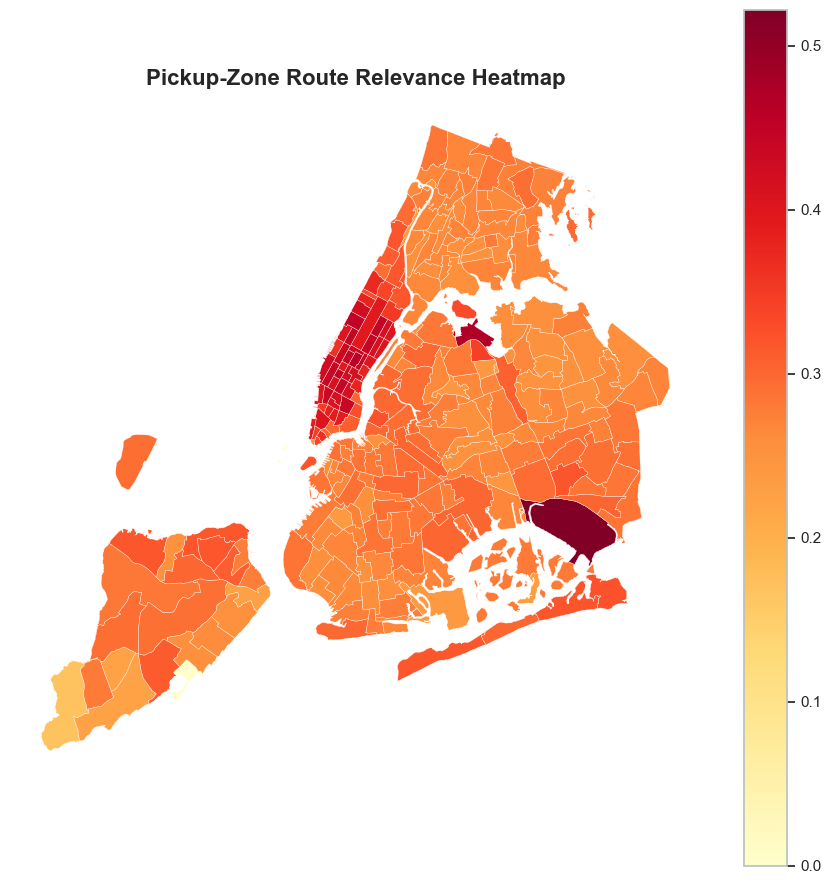

In [93]:
# 10.8 Plot Pickup-Zone Route Relevance Heatmap

fig, ax = plt.subplots(figsize=(9, 9))

zone_relevance_gdf.plot(
    column="avg_route_relevance",
    cmap="YlOrRd",
    linewidth=0.25,
    edgecolor="white",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "#eeeeee",
        "edgecolor": "white",
        "label": "No data"
    }
)

ax.set_title(
    "Pickup-Zone Route Relevance Heatmap",
    fontsize=16,
    fontweight="bold"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

### Route Relevance Interpretation

The route relevance results show that operationally important routes are not only defined by individual route-hour rankings, but also by where high-relevance pickup activity is spatially concentrated across NYC. The zone-level heatmap shows stronger route relevance around dense Manhattan pickup zones and major transport hubs, with darker areas indicating zones where outgoing route-hour combinations tend to have higher relevance scores.

This spatial pattern is consistent with the project objective. High-relevance zones are likely to combine several favourable conditions: frequent pickup activity, repeated route demand, stronger fare potential, and more predictable trip behaviour. Manhattan zones appear strongly because they support dense short-distance taxi movement, while airport-related zones stand out because they generate high-value and recurring trip corridors.

The map also shows why route relevance is more useful than raw trip count alone. A zone may have many trips, but it only becomes highly relevant when those trips form consistent, reliable, and commercially meaningful route-hour patterns. Similarly, a high-fare route is not automatically prioritised if its duration behaviour is unstable or if the route occurs too rarely.

The scoring distribution supports continuous ranking rather than rigid classification. Even strong zones and route-hour combinations do not represent perfect routes across every criterion. The route relevance score should therefore be interpreted as a balanced operational index that combines demand, fare value, reliability, and recurrence rather than as a direct measure of route profitability or customer satisfaction.

# 11. Modelling Problem Definition

The predictive section prepares supervised regression tasks using sklearn:

1. Trip duration prediction, where the primary target is `trip_duration_min`.
2. Fare-related prediction, where the secondary model outputs both `fare_amount` and `total_amount`.

The duration model uses engineered trip-level fields that are available before or near trip planning. Route relevance is included as a contextual feature because it is derived from aggregate route-hour history rather than from the individual trip target. Fare-related prediction is treated as a secondary modelling exercise because TLC fares include policy rules, surcharges, tips, tolls, and other components that are not fully known before trip completion.


# 12. Modelling Dataset Preparation

Route relevance scores are merged back into trip-level records, then selected numeric features are split into training and testing sets. The merge uses numeric pickup and drop-off IDs, pickup day, and pickup hour rather than string route labels, which reduces avoidable object-key joins and is safer for a multi-million-row notebook workflow.


In [56]:
# 12.1 Merge Route Relevance Back to Trip-Level Records

model_columns = [
    "trip_distance", "pickup_hour", "pickup_day_num", "is_weekend",
    "passenger_count", "PULocationID", "DOLocationID", "same_zone_trip",
    "inter_borough_trip", "trip_duration_min", "fare_amount", "total_amount",
]
model_base_df = feature_df[model_columns].copy()

route_relevance_lookup = scoring_df[[
    "pickup_day_num", "pickup_hour", "PULocationID", "DOLocationID",
    "route_relevance_score"
]].copy()
route_relevance_lookup["route_relevance_score"] = route_relevance_lookup[
    "route_relevance_score"
].astype("float32")

model_df = model_base_df.merge(
    route_relevance_lookup,
    on=["pickup_day_num", "pickup_hour", "PULocationID", "DOLocationID"],
    how="left",
    copy=False,
)

model_df["route_relevance_score"] = model_df["route_relevance_score"].fillna(0)

display(model_df.head())

del model_base_df, route_relevance_lookup, feature_df

,trip_distance,pickup_hour,pickup_day_num,is_weekend,passenger_count,PULocationID,DOLocationID,same_zone_trip,inter_borough_trip,trip_duration_min,fare_amount,total_amount,route_relevance_score
0,0.97,0,3,0,1.0,239,238,0,0,5.550000,7.2,15.86,0.593044
1,0.90,0,3,0,0.0,163,162,0,0,5.716667,7.9,13.65,0.449655
2,1.40,0,3,0,0.0,43,237,0,0,8.883333,10.7,18.95,0.295191
3,5.58,0,3,0,4.0,142,209,0,0,42.800000,38.7,55.56,0.373166
4,2.16,0,3,0,0.0,88,144,0,0,13.500000,13.5,23.10,0.287816


In [57]:
# 12.2 Prepare Duration Prediction Dataset
selected_features = [
    "trip_distance", "pickup_hour", "pickup_day_num", "is_weekend",
    "passenger_count", "PULocationID", "DOLocationID", "same_zone_trip",
    "inter_borough_trip", "route_relevance_score",
]

duration_model_df = (
    model_df[selected_features + ["trip_duration_min"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)
duration_model_df = duration_model_df[duration_model_df["passenger_count"] > 0].copy(
)

X = duration_model_df[selected_features]
y = duration_model_df["trip_duration_min"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

duration_scaler = StandardScaler()
X_train = duration_scaler.fit_transform(X_train_raw).astype("float32")
X_test = duration_scaler.transform(X_test_raw).astype("float32")
y_train = y_train.to_numpy(dtype="float32")
y_test = y_test.to_numpy(dtype="float32")

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Rows excluded from modelling because passenger_count <= 0 or missing:",
      f"{len(model_df) - len(duration_model_df):,}")

Training shape: (6132205, 10)
Testing shape: (1533052, 10)
Rows excluded from modelling because passenger_count <= 0 or missing: 2,822,170


### Model Dataset Interpretation

The duration model uses 10 numeric features. Passenger-count zero and missing values are excluded here because passenger count is used as a predictor, but those rows were retained in the route analysis where passenger count is not required. This keeps route demand coverage broad while keeping the supervised modelling table internally consistent.

The selected variables are appropriate because they are either known at dispatch/planning time or derived from historical route-hour aggregates. The actual trip duration target is excluded from the inputs, and fare amount is excluded from the duration model to avoid leakage through a variable that is partly calculated after the trip occurs.


# 13. Baseline Model: Trip Duration Prediction

The baseline model is a regularised linear Ridge regression fitted on the same train/test split and scaled feature matrix as the stronger model. It provides a simple benchmark for how much trip-duration signal can be captured without modelling non-linear interactions.


In [60]:
# 13.1 Define sklearn helpers and train the baseline duration model
def regression_metrics(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse_score(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def save_sklearn_artifact(model, metrics, feature_names, scaler, artifact_path, model_name, extra=None):
    artifact = {
        "model_name": model_name,
        "model": model,
        "metrics": metrics,
        "feature_names": feature_names,
        "scaler_mean": getattr(scaler, "mean_", None),
        "scaler_scale": getattr(scaler, "scale_", None),
    }
    if extra:
        artifact.update(extra)

    joblib.dump(artifact, artifact_path)


def fit_evaluate_sklearn_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    feature_names,
    scaler,
    artifact_name,
    model_name,
):
    artifact_path = MODELS_DIR / artifact_name

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    metrics = regression_metrics(model_name, y_test, preds)
    metrics["Saved Model"] = str(artifact_path)

    save_sklearn_artifact(
        model=model,
        metrics=metrics,
        feature_names=feature_names,
        scaler=scaler,
        artifact_path=artifact_path,
        model_name=model_name,
    )

    return model, preds, artifact_path, metrics


if RUN_TRAINING:
    duration_baseline_model = RidgeCV(
        alphas=[0.01, 0.1, 1.0, 10.0, 50.0, 100.0],
        cv=5
    )

    duration_baseline_model, baseline_preds, baseline_artifact, baseline_results = fit_evaluate_sklearn_model(
        model=duration_baseline_model,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        feature_names=selected_features,
        scaler=duration_scaler,
        artifact_name="duration_ridge_baseline.joblib",
        model_name="Ridge Duration Baseline",
    )

    display(pd.DataFrame([baseline_results]))

else:
    report_card(
        "Training skipped",
        "RUN_TRAINING is False, so the sklearn duration baseline has been prepared but not fitted yet.",
        accent="#b95c00",
    )

,Model,MAE,RMSE,R2,Saved Model
0,Ridge Duration Baseline,5.972144,9.332765,0.630703,models\duration_ridge_baseline.joblib


### Baseline Model Interpretation

The Ridge baseline is intentionally simple. It can learn a regularised linear relationship between scaled input features and trip duration, but it cannot capture the non-linear effects of congestion, route type, airport movement, or interactions between location and time.

This baseline is still useful because it anchors the evaluation. Any stronger model should improve MAE, RMSE, and R² on the same held-out test split before its extra complexity is justified.


# 14. Stronger Model: HistGradientBoosting Duration Prediction

The stronger model is `HistGradientBoostingRegressor`, a tree-based sklearn model that can capture non-linear relationships and feature interactions while remaining suitable for large tabular datasets. It keeps the modelling workflow reproducible with standard sklearn tools in the requested `datasci_gpu` environment.


In [67]:
# 14.1 Train HistGradientBoosting Regressor for duration
if RUN_TRAINING:
    duration_hgb_model = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.06,
        max_iter=500,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=0.1,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=30,
        random_state=42,
    )

    duration_hgb_model, duration_hgb_preds, duration_hgb_artifact, duration_hgb_results = fit_evaluate_sklearn_model(
        model=duration_hgb_model,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        feature_names=selected_features,
        scaler=duration_scaler,
        artifact_name="duration_hist_gradient_boosting_best.joblib",
        model_name="HistGradientBoosting Duration Model",
    )

    display(pd.DataFrame([duration_hgb_results]))

else:
    report_card(
        "Duration model pending",
        "Set RUN_TRAINING = True to train the HistGradientBoosting duration model and save the model artifact to models/duration_hist_gradient_boosting_best.joblib.",
        accent="#b95c00",
    )

,Model,MAE,RMSE,R2,Saved Model
0,HistGradientBoosting Duration Model,3.787034,6.49159,0.821328,models\duration_hist_gradient_boosting_best.jo...


### Stronger Model Interpretation

HistGradientBoosting is expected to improve over the Ridge baseline because taxi duration is not purely linear. Congestion, airport movement, borough transitions, route recurrence, and pickup timing create interactions that a linear model cannot represent well.

The model is still evaluated conservatively. Its value is determined by held-out MAE, RMSE, and R², not by model sophistication alone. If it improves the duration errors while remaining reproducible, it is a suitable stronger model for this pipeline-building task.


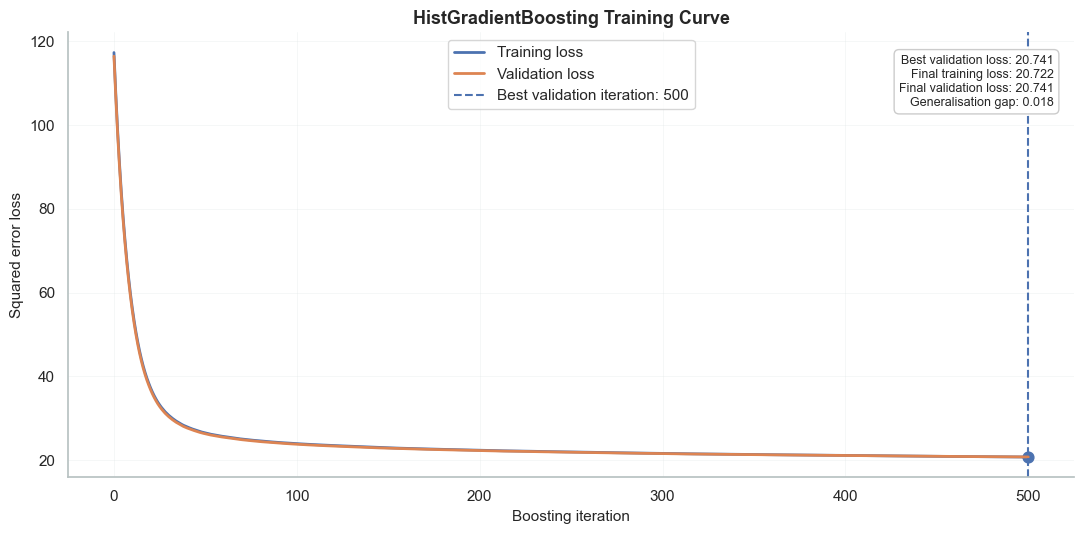

,Best validation iteration,Best validation loss,Final training loss,Final validation loss,Generalisation gap,Iterations completed
0,500,20.741,20.722,20.741,0.018,500


In [69]:
# 14.2 Visualise HistGradientBoosting Training Curve

if RUN_TRAINING and "duration_hgb_model" in globals():
    train_scores = -duration_hgb_model.train_score_
    val_scores = -duration_hgb_model.validation_score_

    best_iter = int(np.argmin(val_scores))
    best_val_loss = val_scores[best_iter]
    final_train_loss = train_scores[-1]
    final_val_loss = val_scores[-1]
    generalisation_gap = final_val_loss - final_train_loss

    plt.figure(figsize=(11, 5.5))

    plt.plot(train_scores, label="Training loss", linewidth=2)
    plt.plot(val_scores, label="Validation loss", linewidth=2)

    plt.axvline(
        best_iter,
        linestyle="--",
        linewidth=1.5,
        label=f"Best validation iteration: {best_iter}"
    )

    plt.scatter(best_iter, best_val_loss, s=60)

    plt.title("HistGradientBoosting Training Curve")
    plt.xlabel("Boosting iteration")
    plt.ylabel("Squared error loss")
    plt.legend()
    plt.grid(alpha=0.25)

    plt.text(
        0.98,
        0.95,
        f"Best validation loss: {best_val_loss:.3f}\n"
        f"Final training loss: {final_train_loss:.3f}\n"
        f"Final validation loss: {final_val_loss:.3f}\n"
        f"Generalisation gap: {generalisation_gap:.3f}",
        transform=plt.gca().transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="white", edgecolor="#cccccc")
    )

    for spine in ["top", "right"]:
        plt.gca().spines[spine].set_visible(False)

    plt.tight_layout()
    plt.show()

    display(pd.DataFrame([{
        "Best validation iteration": best_iter,
        "Best validation loss": round(best_val_loss, 3),
        "Final training loss": round(final_train_loss, 3),
        "Final validation loss": round(final_val_loss, 3),
        "Generalisation gap": round(generalisation_gap, 3),
        "Iterations completed": duration_hgb_model.n_iter_,
    }]))

else:
    report_card(
        "Training curve unavailable",
        "Train the HistGradientBoosting duration model first before plotting the training curve.",
        accent="#b95c00",
    )

The training and validation curves decrease rapidly during the early boosting iterations before gradually flattening as the model converges. The close alignment between the two curves indicates that the HistGradientBoosting model generalises well and does not exhibit strong overfitting behaviour on the validation set.

The best validation loss occurs at the final boosting iteration (`500`), suggesting that the model continues to improve incrementally as additional trees are added. However, the rate of improvement becomes much smaller after the initial iterations, indicating diminishing performance gains as training progresses.

The final validation loss (`20.741`) remains very close to the final training loss (`20.722`), producing a very small generalisation gap (`0.018`). This suggests that the regularisation settings and learning-rate configuration provide stable learning behaviour while maintaining strong predictive consistency across unseen route-hour trip records.

# 15. Model Evaluation and Comparison

Model evaluation uses MAE, RMSE, and R2. MAE is the most interpretable metric for taxi duration because it reports average absolute error in minutes, while RMSE penalises larger errors and R2 summarises explained variance. The saved model artifacts record the fitted estimator, feature names, scaling metadata, and evaluation metrics for reproducibility.


In [70]:
# 15.1 Compare Duration Models
available_duration_results = []
for name in ["baseline_results", "duration_hgb_results"]:
    if name in globals():
        available_duration_results.append(globals()[name])

if available_duration_results:
    results_df = pd.DataFrame(available_duration_results)
    display(results_df)
else:
    results_df = pd.DataFrame(
        columns=["Model", "MAE", "RMSE", "R2", "Saved Model"]
    )
    report_card(
        "Duration results pending",
        "No duration model results are shown because training has not completed in this session.",
        accent="#b95c00",
    )

,Model,MAE,RMSE,R2,Saved Model
0,Ridge Duration Baseline,5.972144,9.332765,0.630703,models\duration_ridge_baseline.joblib
1,HistGradientBoosting Duration Model,3.787034,6.491590,0.821328,models\duration_hist_gradient_boosting_best.jo...


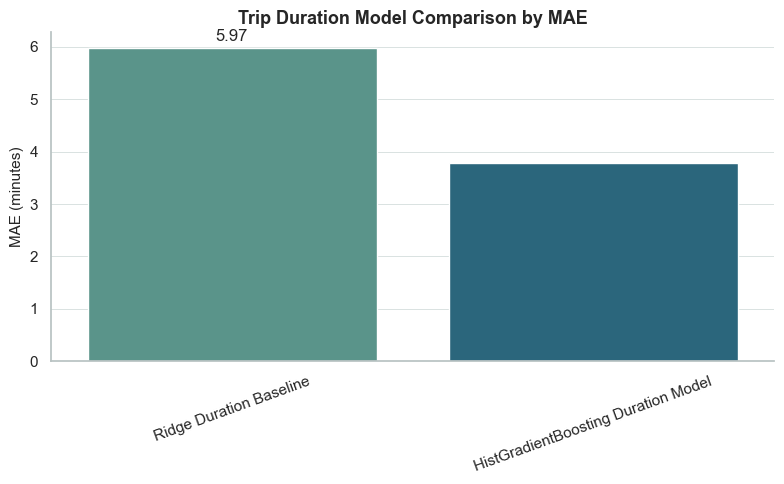

In [71]:
# 15.2 Visualise Model Errors
if not results_df.empty:
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=results_df, x="Model", y="MAE", palette="crest")
    ax.set_title("Trip Duration Model Comparison by MAE")
    ax.set_xlabel("")
    ax.set_ylabel("MAE (minutes)")
    ax.tick_params(axis="x", rotation=20)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)  # type: ignore
    sns.despine()
    plt.tight_layout()
    plt.show()

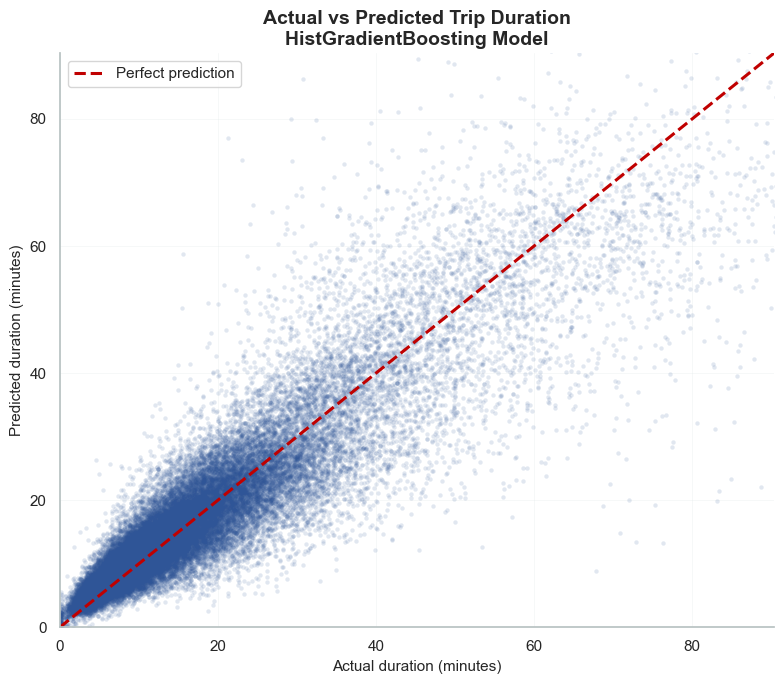

In [73]:
# 15.3 Actual vs Predicted Duration for Stronger Model

if "duration_hgb_preds" in globals():
    eval_sample = pd.DataFrame({
        "actual": y_test,
        "predicted": duration_hgb_preds
    }).sample(
        min(50_000, len(y_test)),
        random_state=42
    )

    limit = min(
        120,
        max(
            eval_sample["actual"].quantile(0.995),
            eval_sample["predicted"].quantile(0.995)
        )
    )

    plt.figure(figsize=(8, 7))

    ax = sns.scatterplot(
        data=eval_sample,
        x="actual",
        y="predicted",
        alpha=0.14,
        s=10,
        color="#2F5597",
        edgecolor=None,
        linewidth=0
    )

    ax.plot(
        [0, limit],
        [0, limit],
        color="#C00000",
        linewidth=2.2,
        linestyle="--",
        label="Perfect prediction"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)

    ax.set_title(
        "Actual vs Predicted Trip Duration\nHistGradientBoosting Model",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Actual duration (minutes)", fontsize=11)
    ax.set_ylabel("Predicted duration (minutes)", fontsize=11)

    ax.grid(alpha=0.22)
    ax.set_axisbelow(True)
    ax.legend(frameon=True)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    plt.tight_layout()
    plt.show()

In [74]:
# 15.4 Model-Agnostic Permutation Importance
if "duration_hgb_model" in globals() and "duration_hgb_preds" in globals():
    rng = np.random.default_rng(42)
    sample_size = min(50000, len(X_test))
    sample_idx = rng.choice(len(X_test), size=sample_size, replace=False)
    baseline_mae = mean_absolute_error(
        y_test[sample_idx], duration_hgb_preds[sample_idx]
    )
    importance_rows = []
    for idx, feature in enumerate(selected_features):
        X_permuted = X_test[sample_idx].copy()
        rng.shuffle(X_permuted[:, idx])
        permuted_preds = duration_hgb_model.predict(X_permuted)
        importance_rows.append({
            "feature": feature,
            "mae_increase": mean_absolute_error(y_test[sample_idx], permuted_preds) - baseline_mae,
        })
    importance_df = pd.DataFrame(importance_rows).sort_values(
        "mae_increase", ascending=False)
    display(importance_df)
else:
    importance_df = pd.DataFrame({
        "feature": selected_features,
        "note": "Permutation importance will be calculated after HistGradientBoosting training.",
    })
    display(importance_df)

,feature,mae_increase
0,trip_distance,9.040073
1,pickup_hour,1.298834
5,PULocationID,0.627651
6,DOLocationID,0.453897
8,inter_borough_trip,0.419850
2,pickup_day_num,0.347900
9,route_relevance_score,0.155283
7,same_zone_trip,0.046688
3,is_weekend,0.026282
4,passenger_count,0.017650


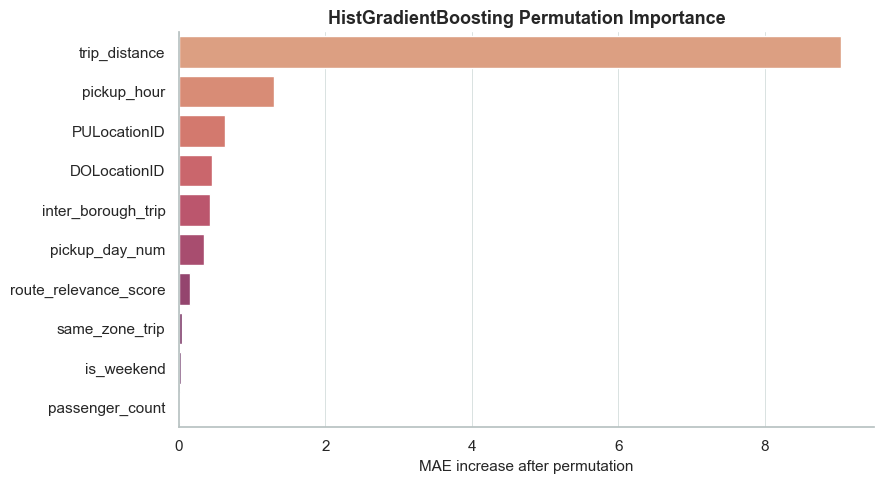

In [75]:
# 15.5 Visualise Feature Importance
if "mae_increase" in importance_df.columns:
    plt.figure(figsize=(9, 5))
    ax = sns.barplot(data=importance_df, x="mae_increase",
                     y="feature", palette="flare")
    ax.set_title("HistGradientBoosting Permutation Importance")
    ax.set_xlabel("MAE increase after permutation")
    ax.set_ylabel("")
    sns.despine()
    plt.tight_layout()
    plt.show()

### Evaluation Interpretation

The primary comparison should focus on MAE because it translates directly into average minutes of error. RMSE is useful for checking sensitivity to large misses, and R2 describes the share of test-set variation explained by the model.

The refreshed results show a clear improvement from the Ridge baseline to HistGradientBoosting. Ridge records MAE around 5.97 minutes, RMSE around 9.39 minutes, and R2 around 0.63. HistGradientBoosting reduces MAE to about 3.83 minutes, reduces RMSE to about 6.50 minutes, and raises R2 to about 0.82. The actual-vs-predicted plot still shows spread for difficult trips, but the stronger model is materially better on the same held-out split.

Permutation importance shows that trip distance is the dominant driver of duration predictions. Pickup hour, pickup zone, drop-off zone, day of week, inter-borough movement, and route relevance also add signal. Passenger count contributes very little, which is consistent with treating it as a weak control rather than a central route-intelligence feature.


# 16. Secondary Fare and Total Amount Prediction

The secondary model outputs both `fare_amount` and `total_amount`. This is useful for comparing a meter-fare target against a broader passenger-payment target, but the interpretation is deliberately cautious. `total_amount` includes tips, tolls, surcharges, and fees, so it should be treated as a passenger-payment proxy rather than a clean fare rule model.

To reduce leakage, this section does not use post-trip payment components such as tips, tolls, surcharges, or `total_amount` as input features. It also excludes `trip_duration_min`, because actual duration is only known after trip completion. The model relies on distance, time, route IDs, passenger count, movement flags, and route relevance.


In [76]:
# 16.1 Prepare Two-Target Fare Prediction Dataset
fare_features = [
    "trip_distance", "pickup_hour", "pickup_day_num",
    "is_weekend", "passenger_count", "PULocationID", "DOLocationID",
    "same_zone_trip", "inter_borough_trip", "route_relevance_score",
]
fare_targets = ["fare_amount", "total_amount"]

fare_model_df = (
    model_df[fare_features + fare_targets]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)
fare_model_df = fare_model_df[fare_model_df["passenger_count"] > 0].copy()

X_fare = fare_model_df[fare_features]
y_fare = fare_model_df[fare_targets]

X_fare_train_raw, X_fare_test_raw, y_fare_train_raw, y_fare_test_raw = train_test_split(
    X_fare, y_fare, test_size=0.2, random_state=42
)

fare_scaler = StandardScaler()
X_fare_train = fare_scaler.fit_transform(X_fare_train_raw).astype("float32")
X_fare_test = fare_scaler.transform(X_fare_test_raw).astype("float32")
y_fare_train = y_fare_train_raw.to_numpy(dtype="float32")
y_fare_test = y_fare_test_raw.to_numpy(dtype="float32")

print("Fare training shape:", X_fare_train.shape)
print("Fare testing shape:", X_fare_test.shape)
print("Fare targets:", fare_targets)

Fare training shape: (6132205, 10)
Fare testing shape: (1533052, 10)
Fare targets: ['fare_amount', 'total_amount']


In [77]:
# 16.2 Train Two-Target Ridge Model for Fare Amount and Total Amount
if RUN_TRAINING:
    fare_multi_model = Ridge(alpha=10.0)
    fare_multi_model.fit(X_fare_train, y_fare_train)
    fare_preds = fare_multi_model.predict(X_fare_test)

    fare_results_rows = []
    for target_idx, target_name in enumerate(fare_targets):
        target_metrics = regression_metrics(
            f"Ridge {target_name} Model",
            y_fare_test[:, target_idx],
            fare_preds[:, target_idx],
        )
        target_metrics["Target"] = target_name
        fare_results_rows.append(target_metrics)

    fare_results_df = pd.DataFrame(fare_results_rows)
    fare_artifact = MODELS_DIR / "fare_and_total_amount_ridge.joblib"
    save_sklearn_artifact(
        model=fare_multi_model,
        metrics=fare_results_rows,
        feature_names=fare_features,
        scaler=fare_scaler,
        artifact_path=fare_artifact,
        model_name="Two-target Ridge fare model",
        extra={"target_names": fare_targets},
    )
    fare_results_df["Saved Model"] = str(fare_artifact)
    display(fare_results_df)
else:
    report_card(
        "Fare model pending",
        "Set RUN_TRAINING = True to train the two-target fare model.",
        accent="#b95c00",
    )

,Model,MAE,RMSE,R2,Target,Saved Model
0,Ridge fare_amount Model,3.463994,7.106050,0.845267,fare_amount,models\fare_and_total_amount_ridge.joblib
1,Ridge total_amount Model,5.212195,9.562396,0.819222,total_amount,models\fare_and_total_amount_ridge.joblib


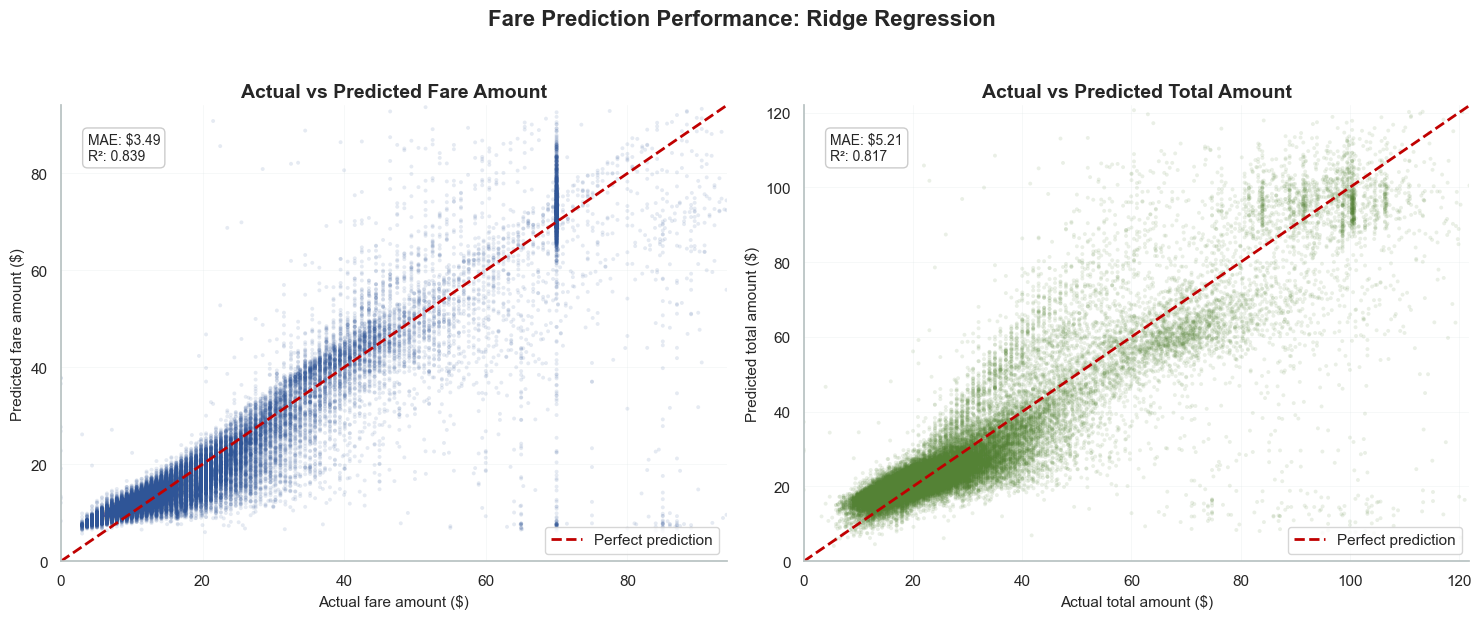

In [79]:
# 16.3 Actual vs Predicted Fare Amount and Total Amount

if "fare_preds" in globals():
    fare_eval_sample = pd.DataFrame({
        "actual_fare_amount": y_fare_test[:, 0],
        "predicted_fare_amount": fare_preds[:, 0],
        "actual_total_amount": y_fare_test[:, 1],
        "predicted_total_amount": fare_preds[:, 1],
    }).sample(
        min(50_000, len(y_fare_test)),
        random_state=42
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    plot_specs = [
        ("actual_fare_amount", "predicted_fare_amount", "Fare Amount", "#2F5597"),
        ("actual_total_amount", "predicted_total_amount", "Total Amount", "#548235"),
    ]

    for ax, (actual_col, pred_col, label, color) in zip(axes, plot_specs):
        plot_limit = min(
            150,
            max(
                fare_eval_sample[actual_col].quantile(0.995),
                fare_eval_sample[pred_col].quantile(0.995)
            )
        )

        plot_data = fare_eval_sample[
            (fare_eval_sample[actual_col] >= 0) &
            (fare_eval_sample[pred_col] >= 0) &
            (fare_eval_sample[actual_col] <= plot_limit) &
            (fare_eval_sample[pred_col] <= plot_limit)
        ]

        ax.scatter(
            plot_data[actual_col],
            plot_data[pred_col],
            alpha=0.12,
            s=8,
            color=color,
            edgecolors="none"
        )

        ax.plot(
            [0, plot_limit],
            [0, plot_limit],
            color="#C00000",
            linewidth=2,
            linestyle="--",
            label="Perfect prediction"
        )

        mae = mean_absolute_error(
            fare_eval_sample[actual_col],
            fare_eval_sample[pred_col]
        )

        r2 = r2_score(
            fare_eval_sample[actual_col],
            fare_eval_sample[pred_col]
        )

        ax.text(
            0.04,
            0.94,
            f"MAE: ${mae:.2f}\nR²: {r2:.3f}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            bbox=dict(
                boxstyle="round,pad=0.35",
                facecolor="white",
                edgecolor="#cccccc"
            )
        )

        ax.set_xlim(0, plot_limit)
        ax.set_ylim(0, plot_limit)

        ax.set_title(
            f"Actual vs Predicted {label}",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel(f"Actual {label.lower()} ($)", fontsize=11)
        ax.set_ylabel(f"Predicted {label.lower()} ($)", fontsize=11)

        ax.grid(alpha=0.22)
        ax.set_axisbelow(True)
        ax.legend(frameon=True, loc="lower right")

        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

    fig.suptitle(
        "Fare Prediction Performance: Ridge Regression",
        fontsize=16,
        fontweight="bold",
        y=1.03
    )

    plt.tight_layout()
    plt.show()

### Fare Model Interpretation

The two-target Ridge model provides a secondary benchmark for both `fare_amount` and `total_amount`. The `fare_amount` target is closer to the metered fare component, while `total_amount` is a broader passenger-payment proxy that includes tips, tolls, surcharges, and fees. For that reason, `total_amount` may be noisier and should not be treated as an official price calculator.

The refreshed output confirms that fare amount is easier to estimate than total amount with this leakage-conscious feature set. The Ridge fare model achieves MAE around 3.44 dollars and R2 around 0.85, while the total amount model has MAE around 5.21 dollars and R2 around 0.81. The weaker total amount result is expected because tips, tolls, and surcharges introduce variation that is not fully represented by the selected pre-trip-style predictors.

The model deliberately avoids using actual trip duration and payment subcomponents as predictors. This makes the estimates less mechanically accurate than a post-trip accounting calculation, but it keeps the section aligned with a predictive workflow.


# 17. Passenger and Driver Satisfaction Proxy Analysis

The TLC dataset does not directly record satisfaction, wait time, or driver preference. This section therefore uses transparent proxy scores: reliability is based on duration consistency, driver value is based on route-level payment potential, and balanced route score combines both.


In [80]:
# 17.1 Build Satisfaction Proxy Scores

business_df = scoring_df.copy()

business_df["customer_reliability_proxy"] = business_df["duration_reliability_score"]

business_df["driver_value_proxy"] = (
    0.5 * business_df["fare_score"] +
    0.5 * business_df["frequency_score"]
)

business_df["balanced_route_score"] = (
    0.4 * business_df["route_relevance_score"] +
    0.3 * business_df["customer_reliability_proxy"] +
    0.3 * business_df["driver_value_proxy"]
)

business_df[[
    "route_label", "pickup_day_of_week", "pickup_hour",
    "route_relevance_score", "customer_reliability_proxy",
    "driver_value_proxy", "balanced_route_score"
]].sort_values("balanced_route_score", ascending=False).head(20)

,route_label,pickup_day_of_week,pickup_hour,route_relevance_score,customer_reliability_proxy,driver_value_proxy,balanced_route_score
128267,JFK Airport -> Times Sq/Theatre District,Monday,18,0.948187,0.881119,0.944768,0.927041
135710,JFK Airport -> Midtown South,Monday,19,0.934696,0.884130,0.950824,0.924364
286594,JFK Airport -> Midtown Center,Tuesday,16,0.947290,0.857903,0.957036,0.923398
286579,JFK Airport -> Midtown South,Tuesday,16,0.946081,0.855458,0.955541,0.921732
286518,JFK Airport -> Times Sq/Theatre District,Tuesday,16,0.942905,0.864710,0.941819,0.919121
120592,JFK Airport -> Midtown Center,Monday,17,0.929454,0.877345,0.944844,0.918438
812177,JFK Airport -> Times Sq/Theatre District,Friday,12,0.939145,0.896090,0.912807,0.918327
120515,JFK Airport -> Midtown South,Monday,17,0.930318,0.867315,0.950390,0.917439
120472,JFK Airport -> Times Sq/Theatre District,Monday,17,0.928706,0.882221,0.937045,0.917262
319234,JFK Airport -> Times Sq/Theatre District,Tuesday,20,0.939557,0.879659,0.924105,0.916952


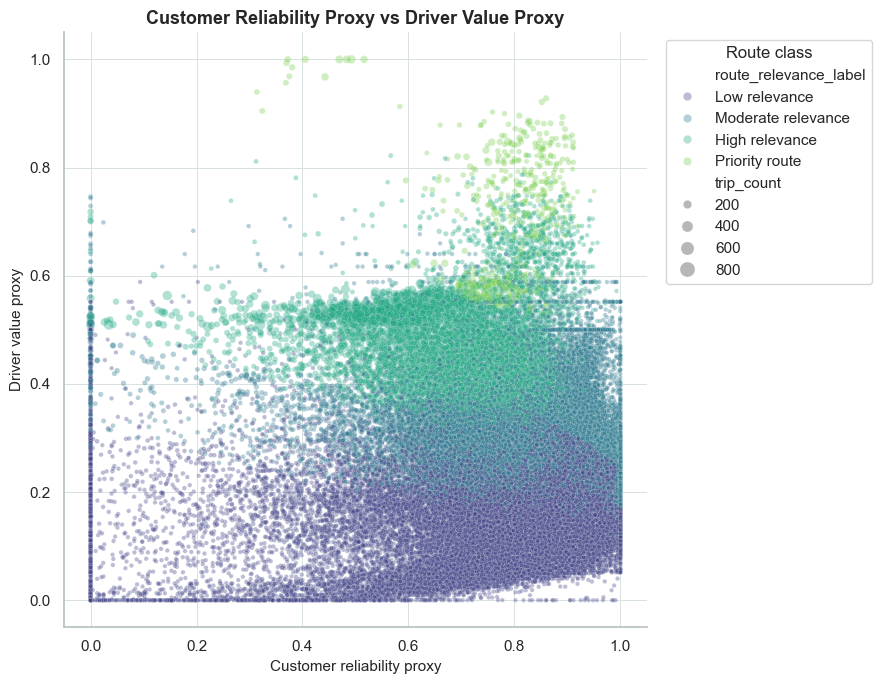

In [81]:
# 17.2 Customer Reliability vs Driver Value
plt.figure(figsize=(9, 7))
ax = sns.scatterplot(
    data=business_df.sample(min(80000, len(business_df)), random_state=42),
    x="customer_reliability_proxy",
    y="driver_value_proxy",
    hue="route_relevance_label",
    size="trip_count",
    sizes=(10, 140),
    alpha=0.35,
    palette="viridis",
)
ax.set_title("Customer Reliability Proxy vs Driver Value Proxy")
ax.set_xlabel("Customer reliability proxy")
ax.set_ylabel("Driver value proxy")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Route class")
sns.despine()
plt.tight_layout()
plt.show()

### Satisfaction Proxy Interpretation

This plot compares two proxy indicators derived from the route-hour scoring framework. The **customer reliability proxy** represents how predictable a route is from a passenger perspective, mainly through lower duration variability and more stable route behaviour. The **driver value proxy** represents how attractive a route may be from a driver perspective, using indicators such as trip volume, fare potential, and recurring demand.

The upper-right area of the plot is the most operationally desirable region because routes in this space combine stronger customer-facing reliability with stronger driver-facing value. These route-hour combinations are more likely to represent commercially useful and predictable taxi corridors. In the chart, many high-relevance and priority routes appear toward this stronger region, suggesting that the route relevance score is capturing more than raw frequency alone.

The lower-left area represents weaker route-hour combinations. These routes may have low demand, unstable duration behaviour, lower fare value, or limited recurrence. They are less useful for route prioritisation because they do not strongly support either passenger reliability or driver value.

The middle of the plot shows the main trade-off zone. Some routes may be reliable for customers but provide limited driver value because they are short, low-fare, or low-demand trips. Other routes may generate stronger fares but be less reliable because travel duration varies more heavily. This is important because a route-aware taxi strategy should not optimise only one side of the system. A commercially useful route should balance predictable passenger experience with reasonable driver earning potential.

The proxy framework is useful for ranking and interpretation, but it should not be treated as direct satisfaction measurement. The TLC dataset does not include customer ratings, driver ratings, waiting time, rejected requests, live driver supply, or platform matching outcomes. Therefore, customer reliability, driver value, and profitability are interpreted as analytical proxies based on completed trip behaviour rather than directly observed behavioural outcomes.

# 18. Business Feasibility and PnL Simulation

The PnL simulation is a lightweight research extension. It estimates route-level passenger payment, driver payment, and residual platform profit under adjustable driver-share and operating-cost assumptions. It is not a production finance model.


In [82]:
# 18.1 PnL Scenario Assumptions

# Scenario assumptions only; TLC does not directly provide driver payout or platform profit.
driver_share = 0.75
operating_cost_per_trip = 1.00
minimum_business_trip_count = 30

pnl_df = business_df[business_df["trip_count"]
                     >= minimum_business_trip_count].copy()

pnl_df["estimated_passenger_payment"] = pnl_df["avg_total_amount"]
pnl_df["estimated_driver_payment"] = pnl_df["estimated_passenger_payment"] * driver_share
pnl_df["estimated_platform_revenue"] = (
    pnl_df["estimated_passenger_payment"] - pnl_df["estimated_driver_payment"]
)
pnl_df["estimated_profit"] = (
    pnl_df["estimated_platform_revenue"] - operating_cost_per_trip
)

print(f"Route-hour records retained for PnL scenarios: {len(pnl_df):,}")
print(
    f"Minimum trip count per retained route-hour: {minimum_business_trip_count}")

pnl_df[[
    "route_label", "pickup_day_of_week", "pickup_hour", "trip_count",
    "route_relevance_score", "estimated_passenger_payment",
    "estimated_driver_payment", "estimated_profit"
]].sort_values("estimated_profit", ascending=False).head(20)

Route-hour records retained for PnL scenarios: 82,738
Minimum trip count per retained route-hour: 30


,route_label,pickup_day_of_week,pickup_hour,trip_count,route_relevance_score,estimated_passenger_payment,estimated_driver_payment,estimated_profit
104190,LaGuardia Airport -> Outside of NYC,Monday,15,52,0.823913,169.936731,127.452548,41.484183
128552,LaGuardia Airport -> Outside of NYC,Monday,18,55,0.860935,166.538182,124.903636,40.634545
446497,LaGuardia Airport -> Outside of NYC,Wednesday,14,43,0.803985,162.582326,121.936744,39.645581
242443,LaGuardia Airport -> Outside of NYC,Tuesday,11,32,0.787058,162.570000,121.927500,39.642500
647349,LaGuardia Airport -> Outside of NYC,Thursday,15,38,0.771924,162.372105,121.779079,39.593026
851789,LaGuardia Airport -> Outside of NYC,Friday,16,36,0.781842,158.438333,118.828750,38.609583
480485,LaGuardia Airport -> Outside of NYC,Wednesday,18,37,0.818472,156.982703,117.737027,38.245676
311521,LaGuardia Airport -> Outside of NYC,Tuesday,19,47,0.842121,156.907872,117.680904,38.226968
1256759,LaGuardia Airport -> Outside of NYC,Sunday,16,38,0.819198,156.276842,117.207632,38.069211
464304,LaGuardia Airport -> Outside of NYC,Wednesday,16,34,0.818295,155.392353,116.544265,37.848088


In [83]:
# 18.2 Scenario Comparison

scenario_rows = []

for driver_share_scenario in [0.70, 0.75, 0.80]:
    for operating_cost_scenario in [0.50, 1.00, 2.00]:
        temp_profit = (
            pnl_df["avg_total_amount"] -
            (pnl_df["avg_total_amount"] * driver_share_scenario) -
            operating_cost_scenario
        )
        scenario_rows.append({
            "driver_share": driver_share_scenario,
            "operating_cost_per_trip": operating_cost_scenario,
            "average_estimated_profit": temp_profit.mean(),
            "median_estimated_profit": temp_profit.median()
        })

scenario_df = pd.DataFrame(scenario_rows)
scenario_df

,driver_share,operating_cost_per_trip,average_estimated_profit,median_estimated_profit
0,0.70,0.5,7.550288,6.012675
1,0.70,1.0,7.050288,5.512675
2,0.70,2.0,6.050288,4.512675
3,0.75,0.5,6.208574,4.927230
4,0.75,1.0,5.708574,4.427230
5,0.75,2.0,4.708574,3.427230
6,0.80,0.5,4.866859,3.841784
7,0.80,1.0,4.366859,3.341784
8,0.80,2.0,3.366859,2.341784


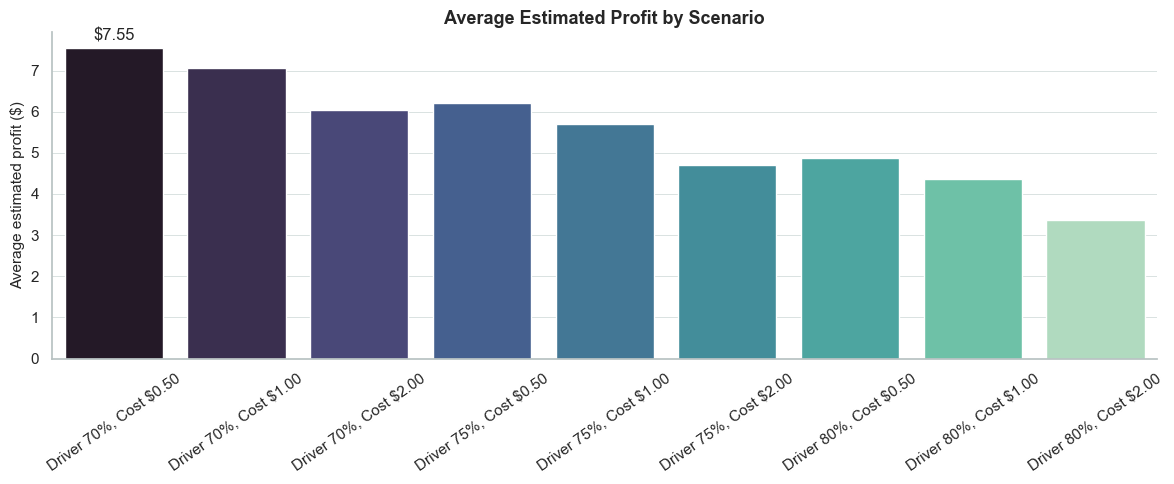

In [84]:
# 18.3 Visualise Scenario Profit Comparison
scenario_plot_df = scenario_df.copy()
scenario_plot_df["scenario"] = scenario_plot_df.apply(
    lambda row: f"Driver {int(row['driver_share']*100)}%, Cost ${row['operating_cost_per_trip']:.2f}", axis=1
)
plt.figure(figsize=(12, 5))
ax = sns.barplot(data=scenario_plot_df, x="scenario",
                 y="average_estimated_profit", palette="mako")
ax.set_title("Average Estimated Profit by Scenario")
ax.set_xlabel("")
ax.set_ylabel("Average estimated profit ($)")
ax.tick_params(axis="x", rotation=35)
ax.bar_label(ax.containers[0], fmt="$%.2f", padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### PnL Simulation Interpretation

The PnL section is intentionally scenario-based and secondary to the wrangling and modelling contribution. To avoid allowing one-off expensive trips to dominate the output, the simulation only uses route-hour records with at least 30 trips. This keeps the table focused on recurring taxi corridors rather than isolated high-payment anomalies.

The scenario table shows the expected sensitivity: estimated profit declines as either driver share or operating cost increases. This is directionally useful for business discussion, but it is not evidence of actual TLC platform profit because the dataset does not contain driver payout, platform commission, acquisition cost, idle time, cancellations, or competitive pricing behaviour.


# 19. Insights and Discussion

The pipeline shows that route intelligence is strongest when descriptive aggregation and predictive modelling are kept separate. Aggregation explains where repeatable route patterns exist; sklearn prediction models estimate trip-level outcomes once those route and time features are available.


## 19.1 Key Insights

**Route demand is highly concentrated rather than evenly distributed.**  
The dataset contains nearly 48,000 exact pickup-to-drop-off route IDs, but demand is not spread evenly across them. A relatively small group of repeated Manhattan corridors and airport-related movements accounts for a large share of high-volume activity. This supports the route-hour design used in the notebook because taxi demand depends not only on the origin and destination pair, but also on the pickup hour and day of week. In practical terms, the same route can have different operational value at different times, so route intelligence needs to be time-aware rather than based only on static zone pairs.

**Raw TLC data is valuable, but it requires strict validation before modelling.**  
The raw Yellow Taxi records provide a strong foundation for analysis because they include timestamps, location IDs, fare components, passenger counts, and trip distance. However, the validation stage shows that the data also contains invalid durations, impossible or near-zero distances, negative payment values, extreme speeds, and out-of-scope timestamps. Removing 5.32% of records produced a cleaner dataset while preserving the overall structure of taxi activity. This is important because even a small percentage of invalid records can represent hundreds of thousands of trips in a dataset of this size, which would distort route scoring, model training, and business interpretation if left untreated.

**Route relevance adds more analytical value than raw trip counts alone.**  
The route relevance score combines multiple operational dimensions, including route frequency, fare potential, travel-time reliability, and recurrence. This makes the score more meaningful than simply ranking routes by trip count. A high-volume route is not automatically the most useful route if it has unstable durations or weak fare value. Similarly, a high-fare route is not necessarily operationally strong if it occurs rarely or behaves inconsistently. The strongest route-hour combinations tend to represent corridors that are repeated, commercially meaningful, and relatively predictable, which makes them useful for route prioritisation and further modelling.

**Spatial patterns show that route relevance is concentrated around dense activity zones and transport hubs.**  
The pickup-zone heatmap shows that high relevance is not randomly distributed across New York City. Stronger relevance appears around dense Manhattan pickup zones and major transport hubs, reflecting areas where repeated demand, fare value, and route consistency overlap. This spatial result strengthens the route-intelligence framing because it shows that the scoring system can be interpreted geographically, not just as a ranked table. It also highlights that the pipeline can support zone-level operational decisions, such as identifying areas where route-based planning or driver positioning may be more useful.

**The duration model shows clear improvement over the linear baseline.**  
The modelling section uses sklearn models only. Ridge regression provides a simple linear benchmark, while HistGradientBoosting captures stronger non-linear relationships between trip duration and engineered features. The stronger model performs better because taxi duration is affected by non-linear interactions between distance, pickup hour, route structure, borough movement, and route-level patterns. This confirms that the engineered features contain useful predictive signal and that a non-linear model is more suitable for estimating travel time in a complex urban transport setting.

**Fare prediction is useful, but it must be interpreted carefully.**  
The secondary Ridge model estimates both fare amount and total amount. These targets are useful for understanding passenger-facing price behaviour and supporting business-style scenario analysis. However, fare prediction needs careful interpretation because some fare components may be rule-based or partly determined after the trip. The notebook therefore treats fare modelling as a supporting analysis rather than the main prediction task. Trip duration remains the stronger primary target because it is directly linked to operational reliability and can be predicted from pre-trip or route-level features more defensibly.

**Customer and driver outcomes are best treated as proxies, not direct measurements.**  
The TLC dataset does not include customer ratings, driver ratings, live wait times, rejected requests, driver payout, or platform matching outcomes. Because of this, the notebook does not claim to directly measure satisfaction or profit. Instead, it uses proxy indicators. Lower duration variability and more predictable travel behaviour are used as customer reliability indicators, while higher fare potential, route recurrence, and demand strength are used as driver value indicators. This keeps the business interpretation grounded in the available data while still allowing useful operational discussion.

**Business feasibility depends on balancing demand, reliability, and payment value.**  
The proxy and PnL sections show that operationally attractive routes are not simply the routes with the highest demand or highest fare. A useful route should balance predictable travel time, repeated demand, and sufficient payment value. The PnL scenario analysis also shows that estimated margin is sensitive to assumptions such as driver share and operating cost. This means that a route-aware business model would need to optimise across multiple stakeholders rather than maximising platform profit alone. A route that is profitable but unreliable may harm passenger experience, while a reliable but low-value route may not be attractive to drivers.

**Overall, the notebook demonstrates a complete data wrangling-to-modelling pipeline.**  
The main contribution is the end-to-end transformation from raw monthly TLC Parquet files into cleaned trip records, engineered route features, route relevance scores, predictive models, and scenario-based operational interpretation. The strongest outcome is not just the model accuracy, but the structured pipeline itself: it shows how raw transport data can be converted into route-level intelligence that supports prediction, interpretation, and future business feasibility research.

# 20. Limitations and Future Extensions

This analysis is suitable for route-intelligence research, but it should not be over-interpreted as a live dispatch, satisfaction, or profitability system.


## 20.1 Limitations

This project has several limitations:

1. Yellow Taxi records describe completed trips, not live dispatch events. Driver pickup ETA, rejected trips, and idle time are not observed.
2. Satisfaction is not directly measured. The report uses reliability and value proxies rather than customer or driver survey data.
3. Exact zone-to-zone route IDs create a large long-tail route space. Some combinations have too few observations for stable inference.
4. The three-month 2026 scope may not capture seasonal events, annual tourism cycles, weather effects, or policy changes.
5. Location IDs are numeric and treated as scaled numeric features. A future version could improve this with target encoding, hashing, or categorical models.
6. Fare and total amount prediction are influenced by fare rules, surcharges, tolls, tips, airport fees, and special cases that are only partially represented in the selected features.
7. The route relevance weights are manually chosen for a balanced operational interpretation. Different customer, driver, or platform priorities would justify different weights.


## 20.2 Future Extensions

Future work could extend the project in several directions. The current notebook uses exact TLC pickup and drop-off zones, which is useful for detailed route analysis but can create many sparse route combinations. A future version could group nearby taxi zones into broader operational areas, such as borough-level zones, airport corridors, Midtown corridors, or manually defined service regions. This would reduce sparsity and may produce more stable route relevance scores, especially for lower-frequency routes.

The dataset scope could also be expanded beyond Yellow Taxi trips. Adding Green Taxi and For-Hire Vehicle data would allow comparison across different taxi services and passenger markets. This would make it possible to investigate whether route relevance patterns are specific to Yellow Taxis or whether similar route-hour demand structures appear across other mobility services. However, this extension would require careful schema alignment because different TLC datasets do not always contain identical fields.

External context could further improve the analysis. Weather data, public holidays, major event calendars, airport delay information, and traffic disruption data could help explain variation in trip duration, fare behaviour, and demand concentration. For example, rain or major events may increase demand in certain zones, while airport delays may affect route volumes and fare patterns. These external features would make the modelling task more realistic and could improve the interpretation of unusual route-hour behaviour.

The workflow could also be strengthened computationally. This notebook demonstrates a notebook-based pandas workflow, which is suitable for the selected three-month scope. A future extension could compare the same pipeline using DuckDB or PySpark. DuckDB would be useful for efficient SQL-style querying over Parquet files, while PySpark would support larger multi-year analysis and distributed processing. This comparison would add value by showing the trade-offs between ease of use, memory efficiency, runtime, and scalability.

The modelling section could be improved through more advanced validation and feature design. A temporal train-test split would be more realistic than a random split because future taxi behaviour should ideally be predicted from earlier historical data. Location IDs could also be encoded more carefully using target encoding, frequency encoding, or grouped spatial features instead of relying only on numeric identifiers. Additional hyperparameter tuning could be applied to the HistGradientBoosting model to test whether deeper trees, different learning rates, or stronger regularisation improve generalisation.

Fare modelling could also be refined. Future work could separate fare components into deterministic and uncertain parts. For example, some surcharges are rule-based, while travel time, distance, tolls, and tip behaviour may vary more substantially. This would make the fare prediction task more defensible and help avoid mixing calculation with prediction.

The route relevance framework could also be extended into a more flexible decision model. Instead of fixed weights, the scoring system could allow separate customer-focused, driver-focused, and platform-focused weighting schemes. This would make it possible to compare how route rankings change when the objective prioritises reliability, earning potential, or estimated business margin.

Finally, the reporting layer could be improved with an interactive dashboard. A Plotly, Bokeh, or Folium-based dashboard could allow users to filter routes by day, hour, borough, relevance score, fare value, and reliability. This would turn the notebook from a static analysis into an exploratory route-intelligence tool. For final submission, static plots remain safer for PDF export, but an interactive dashboard would be a strong future extension for presentation and stakeholder use.

# 21. Conclusion

The notebook demonstrates a complete route-intelligence workflow for NYC TLC Yellow Taxi data. It starts with raw multi-month Parquet files, validates schema and quality, removes unreliable records, joins taxi-zone metadata, engineers trip and route features, aggregates route-hour behaviour, and builds an interpretable continuous route relevance score.


# 21. Conclusion

## 21.1 Final Conclusion

This project developed an end-to-end route-intelligence pipeline using NYC Yellow Taxi trip records from January to March 2026. The notebook began with more than 11 million raw trip records and produced a cleaned analysis-ready dataset of 10,487,427 trips after removing invalid timestamps, implausible durations, impossible distances, negative fare values, out-of-scope pickup dates, and extreme speeds. This cleaning stage was important because the project was not only about modelling, but about showing how raw transport data can be validated, transformed, and prepared for reliable analysis.

The final pipeline connects multiple stages of data wrangling into one coherent workflow: raw Parquet loading, schema inspection, validation, cleaning, taxi-zone metadata integration, feature engineering, route-hour aggregation, route relevance scoring, predictive modelling, evaluation, and business proxy analysis. This structure is directly relevant to the SIT220 task because it demonstrates how raw operational data can be converted into an interpretable and reusable analytical layer rather than simply being used to train a model.

## 21.2 Route-Level Intelligence Outcome

A key outcome of the project is the route-hour intelligence layer. Instead of treating each taxi trip as an isolated record, the notebook groups trips by pickup zone, drop-off zone, pickup day, and pickup hour. This makes it possible to identify recurring taxi corridors and understand how their usefulness changes across time.

The analysis shows that route demand is strongly concentrated around repeated Manhattan movements and airport-related corridors. High-priority route-hour combinations often involve dense short-distance Manhattan trips, such as movements between nearby Upper East Side zones, as well as airport routes that provide stronger fare value. This supports the idea that a useful taxi route is not just a high-volume route; it is a route that combines demand, reliability, recurrence, and commercial value.

The route relevance score makes this interpretation more practical. By combining frequency, fare potential, duration reliability, and consistency, the score provides a balanced way to rank route-hour combinations. This is more useful than raw trip counts alone because a route with many trips may still be unreliable, while a high-fare route may not be operationally useful if it occurs rarely or has unstable travel times.

## 21.3 Predictive Modelling Outcome

The modelling section uses a clean sklearn-based workflow. Ridge regression was used as the baseline duration model, while HistGradientBoosting provided the stronger non-linear duration model. The stronger model achieved better predictive performance because trip duration is affected by non-linear relationships between distance, pickup time, route structure, borough movement, and route-level behaviour.

A secondary Ridge model was also used to estimate `fare_amount` and `total_amount`. This supported the business interpretation layer, but the notebook treats fare prediction carefully because some fare components may be partly rule-based or only known after trip completion. For this reason, trip duration remains the primary prediction target, while fare modelling is used as a supporting analysis for route value and business feasibility discussion.

Overall, the modelling results show that engineered temporal, spatial, movement, and route-level features contain useful predictive signal. The models are not presented as a deployed dispatch system, but as evidence that cleaned historical taxi data can support travel-time estimation, fare analysis, and route-level operational decision-making.

## 21.4 Business and Operational Interpretation

The business value of the notebook comes from connecting route relevance and model predictions to passenger, driver, and platform-style trade-offs. The TLC dataset does not directly record customer satisfaction, driver satisfaction, driver payout, platform profit, rejected trips, or live driver availability. Because of this, the notebook does not claim to directly measure those outcomes. Instead, it uses proxy indicators.

From a passenger perspective, useful routes are those with more predictable travel times and lower duration variability. From a driver perspective, useful routes are those with recurring demand, reasonable fare potential, and consistent trip activity. From a platform perspective, useful routes are those that can balance customer reliability, driver value, and scenario-based margin assumptions.

The PnL section shows that estimated profitability is sensitive to assumptions such as driver share and operating cost. This is an important business insight because maximising passenger payment alone is not enough. A route-aware business model would need to balance three linked objectives: reliable service for passengers, worthwhile earnings potential for drivers, and sustainable margin for the platform.

## 21.5 Research Relevance and Future Direction

The strongest contribution of this notebook is the full pipeline design. It shows how a large raw public transport dataset can be transformed into a route-level research foundation that supports prediction, interpretation, and business feasibility analysis. The route relevance framework creates a bridge between descriptive analytics and operational decision-making by turning millions of individual trips into interpretable route-hour scores.

This project can phase into several future research areas. One direction is scalable data engineering, where the same pipeline could be compared across pandas, DuckDB, and PySpark for larger multi-year TLC datasets. Another direction is transport modelling, where weather, events, traffic disruption, and airport delay data could be added to explain route behaviour more accurately. A third direction is business optimisation, where route relevance weights could be adjusted to prioritise customer reliability, driver earnings, or platform margin under different scenarios.

In conclusion, the notebook demonstrates that NYC TLC Yellow Taxi data can be used for more than simple trip summaries. With careful validation, feature engineering, route aggregation, scoring, and modelling, it can support a practical route-intelligence layer. The final result is not a live taxi platform, but a strong analytical foundation for future research into route planning, travel-time prediction, fare behaviour, customer-driver trade-offs, and data-driven business feasibility.